In [1]:
from snowflake.snowpark import Session
from snowflake.snowpark.functions import col

# local_testing=True means no Snowflake connection is needed
session = Session.builder.config("local_testing", True).create()

In [2]:
df = session.create_dataframe(
    [("Alice", 30), ("Bob", 25), ("Carol", 35)],
    schema=["name", "age"],
)

df

In [3]:
# Filter and select
result = df.filter(col("age") > 26).select("name", "age")
result.show()

------------------
|"NAME"  |"AGE"  |
------------------
|Alice   |30     |
|Carol   |35     |
------------------



In [4]:
# Add a computed column
df.with_column("age_next_year", col("age") + 1).show()

# session.close()

------------------------------------
|"NAME"  |"AGE"  |"AGE_NEXT_YEAR"  |
------------------------------------
|Alice   |30     |31               |
|Bob     |25     |26               |
|Carol   |35     |36               |
------------------------------------



In [5]:
# Import python packages
import snowflake.snowpark.types as T
import snowflake.snowpark.functions as F

# We can also use Snowpark for our analyses!
from snowflake.snowpark.context import get_active_session
session = get_active_session()

In [6]:
session

```python
from snowflake.snowpark import Session

connection_params = {
    "account": "your_org-your_account",   # e.g. myorg-myaccount
    "user": "YOUR_USERNAME",
    "password": "YOUR_PASSWORD",
    "role": "YOUR_ROLE",                  # e.g. ACCOUNTADMIN or SYSADMIN
    "warehouse": "YOUR_WAREHOUSE",        # e.g. COMPUTE_WH
    "database": "YOUR_DATABASE",
    "schema": "YOUR_SCHEMA",              # e.g. PUBLIC
}

session = Session.builder.configs(connection_params).create()

# Quick sanity check
print(session.sql("SELECT CURRENT_USER(), CURRENT_ROLE(), CURRENT_WAREHOUSE()").collect())

# Query a real table
# df = session.table("YOUR_TABLE")
# df.show()

session.close()
```

In [7]:
from dotenv import load_dotenv
load_dotenv()

True

```python
import os
from dotenv import load_dotenv
from snowflake.snowpark import Session

load_dotenv()  # reads the .env file

connection_params = {
    "account": os.environ["SNOWFLAKE_ACCOUNT"],
    "user": os.environ["SNOWFLAKE_USER"],
    "password": os.environ["SNOWFLAKE_PASSWORD"],
    "role": os.environ["SNOWFLAKE_ROLE"],
    "warehouse": os.environ["SNOWFLAKE_WAREHOUSE"],
    "database": os.environ["SNOWFLAKE_DATABASE"],
    "schema": os.environ["SNOWFLAKE_SCHEMA"],
}

session = Session.builder.configs(connection_params).create()
print(session.sql("SELECT CURRENT_USER(), CURRENT_ROLE(), CURRENT_WAREHOUSE()").collect())
session.close()
```

In [8]:
from snowflake.ingest.streaming import StreamingIngestClient

In [9]:
import os
from dotenv import load_dotenv
load_dotenv(override=True)

print(os.environ["SNOWFLAKE_ACCOUNT"])   # should be your real identifier
print(os.environ["SNOWFLAKE_ROLE"])      # should be ZOMATO_LOADER

HKUJMOY-CR34989
ZOMATO_LOADER


In [15]:
from cryptography.hazmat.primitives.asymmetric import rsa
from cryptography.hazmat.primitives import serialization

key = rsa.generate_private_key(public_exponent=65537, key_size=2048)

# 1. Save the PRIVATE key (stays on your PC, never paste it anywhere)
with open("rsa_key.p8", "wb") as f:
    f.write(key.private_bytes(
        serialization.Encoding.PEM,
        serialization.PrivateFormat.PKCS8,
        serialization.NoEncryption()))

# 2. Build the PUBLIC key as one line
pub = key.public_key().public_bytes(
    serialization.Encoding.PEM,
    serialization.PublicFormat.SubjectPublicKeyInfo).decode()
pub_one_line = "".join(pub.strip().splitlines()[1:-1])

print(f"ALTER USER DBT_USER SET RSA_PUBLIC_KEY='{pub_one_line}';")

ALTER USER DBT_USER SET RSA_PUBLIC_KEY='MIIBIjANBgkqhkiG9w0BAQEFAAOCAQ8AMIIBCgKCAQEAx2DhOnZrYjGqzJXunKbFrQyM0/CANUyiXnANPnO1jCN+xDe8UK+d29mLc5Kpkja25g/kLZ4OZ0aTwWShJT0Iy1BcM4b+5tySiDhT330LHkuHXr4ce1+v3drFogv8lp0ddoiY8T/Lv776RfxG8rmffL0UNpLDeFQK3TQE2DwgLgKc4IAWu700EhiDkaAVPm68BnCNkUUsZOAZ7UMP8z/lbqof+0h3/mi4HNwl/sQ7+rzntmHsAPIAYZiq3k+jgV8XZ92a8OEgDsqSOg/fpohJn+xoDlaAvckux1f1iXlstpyy2eceRbWalpXFoRvlgRXwKKqbsndwa6M/X6n6lz7xfwIDAQAB';


In [11]:
import os
from pathlib import Path
from dotenv import load_dotenv
from cryptography.hazmat.primitives import serialization

load_dotenv(override=True)
key_path = Path(os.environ["SNOWFLAKE_PRIVATE_KEY_PATH"]).resolve()

with open(key_path, "rb") as f:
    pk = serialization.load_pem_private_key(f.read(), password=None)

pub = pk.public_key().public_bytes(
    serialization.Encoding.PEM,
    serialization.PublicFormat.SubjectPublicKeyInfo).decode()
one_line = "".join(pub.strip().splitlines()[1:-1])

print("USER in .env:", os.environ["SNOWFLAKE_USER"])
print("KEY FILE    :", key_path)
print()
print("USE ROLE ACCOUNTADMIN;")
print(f"ALTER USER DBT_USER SET RSA_PUBLIC_KEY='{one_line}';")
print("GRANT ROLE ZOMATO_LOADER TO USER DBT_USER;")
print("DESC USER DBT_USER;")

USER in .env: TAOFEEKOLAWOYE391@GMAIL.COM
KEY FILE    : C:\Users\user\Desktop\snowflake_lesson\snowpark_tut\rsa_key.p8

USE ROLE ACCOUNTADMIN;
ALTER USER DBT_USER SET RSA_PUBLIC_KEY='MIIBIjANBgkqhkiG9w0BAQEFAAOCAQ8AMIIBCgKCAQEAx2DhOnZrYjGqzJXunKbFrQyM0/CANUyiXnANPnO1jCN+xDe8UK+d29mLc5Kpkja25g/kLZ4OZ0aTwWShJT0Iy1BcM4b+5tySiDhT330LHkuHXr4ce1+v3drFogv8lp0ddoiY8T/Lv776RfxG8rmffL0UNpLDeFQK3TQE2DwgLgKc4IAWu700EhiDkaAVPm68BnCNkUUsZOAZ7UMP8z/lbqof+0h3/mi4HNwl/sQ7+rzntmHsAPIAYZiq3k+jgV8XZ92a8OEgDsqSOg/fpohJn+xoDlaAvckux1f1iXlstpyy2eceRbWalpXFoRvlgRXwKKqbsndwa6M/X6n6lz7xfwIDAQAB';
GRANT ROLE ZOMATO_LOADER TO USER DBT_USER;
DESC USER DBT_USER;


In [13]:
import os, base64, hashlib
from pathlib import Path
from dotenv import load_dotenv
from cryptography.hazmat.primitives import serialization
from snowflake.snowpark import Session

load_dotenv(override=True)

# --- Checks ---------------------------------------------------------
key_path = Path(os.environ["SNOWFLAKE_PRIVATE_KEY_PATH"]).expanduser().resolve()
if not key_path.exists():
    raise FileNotFoundError(f"Private key not found: {key_path}")

with open(key_path, "rb") as f:
    private_key = serialization.load_pem_private_key(f.read(), password=None)

der = private_key.public_key().public_bytes(
    serialization.Encoding.DER,
    serialization.PublicFormat.SubjectPublicKeyInfo,
)
fp = "SHA256:" + base64.b64encode(hashlib.sha256(der).digest()).decode()

print("User    :", os.environ["SNOWFLAKE_USER"])
print("Key file:", key_path)
print("Key FP  :", fp, "<- must match RSA_PUBLIC_KEY_FP in DESC USER")

# --- Connect --------------------------------------------------------
params = {
    "account":   os.environ["SNOWFLAKE_ACCOUNT"],
    "user":      os.environ["SNOWFLAKE_USER"],
    "private_key_file": str(key_path),
    "authenticator": "SNOWFLAKE_JWT",
    "role":      os.environ["SNOWFLAKE_ROLE"],
    "warehouse": os.environ["SNOWFLAKE_WAREHOUSE"],
    "database":  os.environ["SNOWFLAKE_DATABASE"],
    "schema":    os.environ["SNOWFLAKE_SCHEMA"],
}

session = Session.builder.configs(params).create()

print(session.sql(
    "SELECT CURRENT_USER(), CURRENT_ROLE(), CURRENT_WAREHOUSE(), CURRENT_DATABASE(), CURRENT_SCHEMA()"
).collect())

User    : DBT_USER
Key file: C:\Users\user\Desktop\snowflake_lesson\snowpark_tut\rsa_key.p8
Key FP  : SHA256:Au08GysA8m4McRxyqtiZQi3iQhDLOVtXXTGMPkl0KZo= <- must match RSA_PUBLIC_KEY_FP in DESC USER
[Row(CURRENT_USER()='DBT_USER', CURRENT_ROLE()='ZOMATO_LOADER', CURRENT_WAREHOUSE()='WH_LOAD', CURRENT_DATABASE()='ZOMATO_RAW', CURRENT_SCHEMA()='SANDBOX')]


In [14]:
import pandas as pd

pdf = pd.read_csv(r"C:\Users\user\Desktop\zomato-intelligence\data\order_items.csv")
pdf.columns = [c.upper() for c in pdf.columns]

session.write_pandas(
    pdf,
    table_name="ORDER_ITEMS_SANDBOX",
    auto_create_table=True,
    overwrite=True,
)

df = session.table("ORDER_ITEMS_SANDBOX")

In [15]:
session.sql("SHOW TABLES IN SCHEMA ZOMATO_RAW.SANDBOX").show()

-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
|"created_on"                      |"name"               |"database_name"  |"schema_name"  |"kind"  |"comment"  |"cluster_by"  |"rows"    |"bytes"    |"owner"        |"retention_time"  |"automatic_clustering"  |"change_tracking"  |"search_optimization"  |"search_optimization_progress"  |"search_optimization_bytes"  |"is_external"  |"enable_schema_evolution"  |"owner_role_type"  |"is_event"  |"is_hybrid"  |"is_iceberg"  |"is_dynamic"  |"is_immutable"  |"is_interactive"  |"row_timestam

In [16]:
df.show(5)

-------------------------------------------------------------------------------------------
|"ORDER_ITEM_ID"  |"ORDER_ID"  |"R_ID"  |"F_ID"    |"PRICE"  |"QUANTITY"  |"LINE_AMOUNT"  |
-------------------------------------------------------------------------------------------
|135170           |58745       |350252  |fd185640  |73       |1           |73             |
|135177           |58749       |244989  |fd103916  |169      |1           |169            |
|135184           |58753       |105515  |fd167367  |160      |2           |320            |
|135191           |58757       |158681  |fd309389  |397      |1           |397            |
|135198           |58760       |388235  |fd212950  |181      |2           |362            |
-------------------------------------------------------------------------------------------



In [17]:
session.sql("""
    CREATE TABLE IF NOT EXISTS ZOMATO_RAW.SANDBOX.FIRST_TABLE (
        AGE NUMBER(3,0),
        GENDER VARCHAR(10)
    )
""").collect()

session.sql("INSERT INTO ZOMATO_RAW.SANDBOX.FIRST_TABLE VALUES (20, 'Male')").collect()

[Row(number of rows inserted=1)]

In [18]:
df = session.sql("SELECT * FROM ZOMATO_RAW.SANDBOX.FIRST_TABLE")
df.show()

--------------------
|"AGE"  |"GENDER"  |
--------------------
|20     |Male      |
|20     |Male      |
--------------------



In [19]:
# or insert with a DataFrame
df = session.create_dataframe([[25, "Female"], [31, "Male"]], schema=["AGE", "GENDER"])
df.write.mode("append").save_as_table("ZOMATO_RAW.SANDBOX.SECOND_TABLE")

In [20]:
df = session.sql("SELECT * FROM ZOMATO_RAW.SANDBOX.SECOND_TABLE")
df.show()

--------------------
|"AGE"  |"GENDER"  |
--------------------
|25     |Female    |
|31     |Male      |
|25     |Female    |
|31     |Male      |
--------------------



In [21]:
df = session.sql("SELECT GENDER, COUNT(*) from ZOMATO_RAW.SANDBOX.SECOND_TABLE GROUP BY GENDER")
df.show()

-------------------------
|"GENDER"  |"COUNT(*)"  |
-------------------------
|Female    |2           |
|Male      |2           |
-------------------------



In [22]:
from snowflake.snowpark.functions import col, count

df = (
    session.table("ZOMATO_RAW.SANDBOX.SECOND_TABLE")
    .group_by("GENDER")
    .agg(count("*").alias("COUNT"))
)
df.show()

----------------------
|"GENDER"  |"COUNT"  |
----------------------
|Female    |2        |
|Male      |2        |
----------------------



In [23]:
from snowflake.snowpark.functions import count, avg, min, max

(
    session.table("ZOMATO_RAW.SANDBOX.SECOND_TABLE")
    .group_by("GENDER")
    .agg(
        count("*").alias("CNT"),
        avg("AGE").alias("AVG_AGE"),
        min("AGE").alias("MIN_AGE"),
        max("AGE").alias("MAX_AGE"),
    )
    .sort(col("MAX_AGE").desc())
    .show()
)

--------------------------------------------------------
|"GENDER"  |"CNT"  |"AVG_AGE"  |"MIN_AGE"  |"MAX_AGE"  |
--------------------------------------------------------
|Male      |2      |31.000000  |31         |31         |
|Female    |2      |25.000000  |25         |25         |
--------------------------------------------------------



In [24]:
# WHERE: filter rows before grouping
session.table("ZOMATO_RAW.SANDBOX.SECOND_TABLE") \
    .filter(col("AGE") > 25) \
    .group_by("GENDER").agg(count("*").alias("CNT")).show()

# HAVING: filter groups after aggregating
session.table("ZOMATO_RAW.SANDBOX.SECOND_TABLE") \
    .group_by("GENDER").agg(count("*").alias("CNT")) \
    .filter(col("CNT") > 1).show()

--------------------
|"GENDER"  |"CNT"  |
--------------------
|Male      |2      |
--------------------

--------------------
|"GENDER"  |"CNT"  |
--------------------
|Female    |2      |
|Male      |2      |
--------------------



In [26]:
session.use_role("SYSADMIN")
session.use_warehouse("WH_LOAD")

# 1. Database
session.sql("CREATE DATABASE IF NOT EXISTS EXERCISE_DB").collect()
session.use_database("EXERCISE_DB")
session.use_schema("PUBLIC")

# 2. Table
session.sql("""
    CREATE OR REPLACE TABLE CUSTOMERS (
        ID INT, FIRST_NAME VARCHAR, LAST_NAME VARCHAR,
        EMAIL VARCHAR, AGE INT, CITY VARCHAR
    )
""").collect()

# 3. Load
session.sql("""
    CREATE OR REPLACE FILE FORMAT CSV_COMMA
        TYPE = CSV FIELD_DELIMITER = ',' SKIP_HEADER = 1
""").collect()

session.sql("""
    CREATE OR REPLACE STAGE CUSTOMERS_STAGE
        URL = 's3://snowflake-assignments-mc/gettingstarted/'
        FILE_FORMAT = CSV_COMMA
""").collect()

print(session.sql("""
    COPY INTO CUSTOMERS FROM @CUSTOMERS_STAGE FILES = ('customers.csv')
""").collect())

# 4. Count
print(session.table("CUSTOMERS").count())

[Row(file='s3://snowflake-assignments-mc/gettingstarted/customers.csv', status='LOADED', rows_parsed=1000, rows_loaded=1000, error_limit=1, errors_seen=0, first_error=None, first_error_line=None, first_error_character=None, first_error_column_name=None)]
1000


In [27]:
from snowflake.core import Root, CreateMode
from snowflake.core.database import Database
from snowflake.core.table import Table, TableColumn
from snowflake.snowpark.types import StructType, StructField, IntegerType, StringType

session.use_role("SYSADMIN")
session.use_warehouse("WH_LOAD")
root = Root(session)

# 1. Database
root.databases.create(Database(name="EXERCISE_DB"), mode=CreateMode.if_not_exists)
session.use_database("EXERCISE_DB")
session.use_schema("PUBLIC")

# 2. Table
root.databases["EXERCISE_DB"].schemas["PUBLIC"].tables.create(
    Table(
        name="CUSTOMERS",
        columns=[
            TableColumn(name="ID", datatype="int"),
            TableColumn(name="FIRST_NAME", datatype="string"),
            TableColumn(name="LAST_NAME", datatype="string"),
            TableColumn(name="EMAIL", datatype="string"),
            TableColumn(name="AGE", datatype="int"),
            TableColumn(name="CITY", datatype="string"),
        ],
    ),
    mode=CreateMode.or_replace,
)

# 3a. Stage (no DataFrame API for this, so a small SQL string)
session.sql("""
    CREATE OR REPLACE STAGE CUSTOMERS_STAGE
        URL = 's3://snowflake-assignments-mc/gettingstarted/'
""").collect()

# 3b. Load with the Snowpark reader
csv_schema = StructType([
    StructField("ID", IntegerType()),
    StructField("FIRST_NAME", StringType()),
    StructField("LAST_NAME", StringType()),
    StructField("EMAIL", StringType()),
    StructField("AGE", IntegerType()),
    StructField("CITY", StringType()),
])

df = (
    session.read
    .schema(csv_schema)
    .options({"FIELD_DELIMITER": ",", "SKIP_HEADER": 1})
    .csv("@CUSTOMERS_STAGE/customers.csv")
)

print(df.copy_into_table("CUSTOMERS"))   # runs the COPY and prints the result

# 4. Count
print(session.table("CUSTOMERS").count())

[Row(file='s3://snowflake-assignments-mc/gettingstarted/customers.csv', status='LOADED', rows_parsed=1000, rows_loaded=1000, error_limit=1, errors_seen=0, first_error=None, first_error_line=None, first_error_character=None, first_error_column_name=None)]
1000


In [29]:
session

In [30]:
session.sql("USE WAREHOUSE WH_LOAD;").collect()

[Row(status='Statement executed successfully.')]

In [ ]:
db_customers = session.table("SNOWFLAKE_SAMPLE_DATA.TPCH_SF1.CUSTOMER")

In [22]:
(db_customers.filter(col("C_MKTSEGMENT") == 'HOUSEHOLD')
   .select(col("C_NAME"), col("C_ADDRESS")).show())

----------------------------------------------------------
|"C_NAME"            |"C_ADDRESS"                        |
----------------------------------------------------------
|Customer#000060001  |9Ii4zQn9cX                         |
|Customer#000060010  |c4vEEaV1tdqLdw2oVuXp BN            |
|Customer#000060016  |i5JCEL8FRYSLvOs1Lkqn30a,1jherLDP   |
|Customer#000060021  |KsKuSbEyZEenCWB7F1uMaOm54bciBqZfU  |
|Customer#000060024  |7JBly7LjGnzGYfJCcPeyIoqIwWda       |
|Customer#000060038  | FBvBksLyQsKovVujfq8XQ             |
|Customer#000060043  |6SLQTGRhNJBKEJl9aekego5iwHgy       |
|Customer#000060047  |FETxgdO1 Nn,HkjnlMNx3dvUrM4qMlf    |
|Customer#000060048  |72pgkyyStsx2                       |
|Customer#000060052  |jygrlXgrjEIaVsH14eKreo,ldCsK       |
----------------------------------------------------------



In [24]:
df_customer_Select = (db_customers.filter(col("C_MKTSEGMENT") == 'HOUSEHOLD')
   .select(col("C_NAME"), col("C_ADDRESS")).describe().sort("SUMMARY"))

df_customer_Select.show()

----------------------------------------------------------------------------
|"SUMMARY"  |"C_NAME"            |"C_ADDRESS"                              |
----------------------------------------------------------------------------
|count      |30189               |30189                                    |
|max        |Customer#000149994  |zzp OQy5Or22XP4QxS                       |
|mean       |NULL                |NULL                                     |
|min        |Customer#000000005  |  1Ur sAbsaAHmBcIelil9U85KIXmyQkdyT,qop  |
|stddev     |NULL                |NULL                                     |
----------------------------------------------------------------------------



### Creating stage

In [ ]:
session.sql("CREATE OR REPLACE DATABASE MANAGED_DB").collect()
session.sql("USE DATABASE MANAGED_DB").collect()
session.sql("CREATE OR REPLACE SCHEMA MANAGED_DB.external_staging").collect()

session.sql("""
    CREATE OR REPLACE STAGE MANAGED_DB.external_staging.aws_stage
      URL = 's3://bucketsnowflake3/'
      CREDENTIALS = (AWS_KEY_ID = 'ABCD_dummy_id' AWS_SECRET_KEY = '1234abcd_key')
""").collect()

session.sql("DESC STAGE MANAGED_DB.external_staging.aws_stage").collect()

[Row(parent_property='STAGE_FILE_FORMAT', property='TYPE', property_type='String', property_value='CSV', property_default='CSV'),
 Row(parent_property='STAGE_FILE_FORMAT', property='RECORD_DELIMITER', property_type='String', property_value='\\n', property_default='\\n'),
 Row(parent_property='STAGE_FILE_FORMAT', property='FIELD_DELIMITER', property_type='String', property_value=',', property_default=','),
 Row(parent_property='STAGE_FILE_FORMAT', property='FILE_EXTENSION', property_type='String', property_value='', property_default=''),
 Row(parent_property='STAGE_FILE_FORMAT', property='SKIP_HEADER', property_type='Integer', property_value='0', property_default='0'),
 Row(parent_property='STAGE_FILE_FORMAT', property='PARSE_HEADER', property_type='Boolean', property_value='false', property_default='false'),
 Row(parent_property='STAGE_FILE_FORMAT', property='DATE_FORMAT', property_type='String', property_value='AUTO', property_default='AUTO'),
 Row(parent_property='STAGE_FILE_FORMAT',

In [45]:
session.sql("""
    CREATE OR REPLACE STAGE MANAGED_DB.external_staging.aws_stage
      URL = 's3://bucketsnowflakes3/'
""").collect()

[Row(status='Stage area AWS_STAGE successfully created.')]

In [46]:
session.sql("LIST @MANAGED_DB.external_staging.aws_stage").collect()

[Row(name='s3://bucketsnowflakes3/Loan_payments_data.csv', size=44417, md5='f354864a37b2dbec495190058d427285', last_modified='Mon, 5 Apr 2021 12:28:12 GMT'),
 Row(name='s3://bucketsnowflakes3/OrderDetails.csv', size=54600, md5='1a1c4a47a8e8e43ecef5bf8a46ee4017', last_modified='Tue, 6 Apr 2021 16:42:56 GMT'),
 Row(name='s3://bucketsnowflakes3/sampledata.csv', size=158, md5='462259b257e0238ff9f9fb08313c2637', last_modified='Tue, 6 Apr 2021 16:56:32 GMT')]

In [47]:
session.sql("CREATE OR REPLACE DATABASE TESTING_DB").collect()

session.sql(
    """
    CREATE OR REPLACE TABLE TESTING_DB.PUBLIC.ORDERS (
       ORDER_ID VARCHAR(30),
       AMOUNT INT,
       PROFIT INT,
       QUANTITY INT,
       CATEGORY VARCHAR(30),
       SUBCATEGORY VARCHAR(30)
    )
"""
).collect()

session.sql("SELECT * FROM TESTING_DB.PUBLIC.ORDERS").collect()

[]

In [48]:
session.sql("CREATE SCHEMA IF NOT EXISTS MANAGED_DB.file_formats").collect()

[Row(status='Schema FILE_FORMATS successfully created.')]

In [49]:
session.sql("""
  CREATE OR REPLACE FILE FORMAT MANAGED_DB.file_formats.csv_peek
    TYPE = CSV  FIELD_OPTIONALLY_ENCLOSED_BY = '"'
""").collect()

[Row(status='File format CSV_PEEK successfully created.')]

In [50]:
session.sql("""
  SELECT $1, $2, $3, $4, $5, $6
  FROM @MANAGED_DB.external_staging.aws_stage/OrderDetails.csv
       (FILE_FORMAT => 'MANAGED_DB.file_formats.csv_peek')
  LIMIT 5
""").to_pandas()

,$1,$2,$3,$4,$5,$6
0,Order ID,Amount,Profit,Quantity,Category,Sub-Category
1,B-25601,1275,-1148,7,Furniture,Bookcases
2,B-25601,66,-12,5,Clothing,Stole
3,B-25601,8,-2,3,Clothing,Hankerchief
4,B-25601,80,-56,4,Electronics,Electronic Games


In [51]:
session.sql(
    """
    COPY INTO TESTING_DB.PUBLIC.ORDERS
    FROM @MANAGED_DB.external_staging.aws_stage/OrderDetails.csv
    file_format = (type=csv field_delimiter=',' skip_header=1
                NULL_IF = ('', 'NULL')  EMPTY_FIELD_AS_NULL = TRUE
            )
    """
).collect()

[Row(file='s3://bucketsnowflakes3/OrderDetails.csv', status='LOADED', rows_parsed=1500, rows_loaded=1500, error_limit=1, errors_seen=0, first_error=None, first_error_line=None, first_error_character=None, first_error_column_name=None)]

In [53]:
session.sql("SELECT * FROM TESTING_DB.PUBLIC.ORDERS LIMIT 10").to_pandas()

,ORDER_ID,AMOUNT,PROFIT,QUANTITY,CATEGORY,SUBCATEGORY
0,B-25601,1275,-1148,7,Furniture,Bookcases
1,B-25601,66,-12,5,Clothing,Stole
2,B-25601,8,-2,3,Clothing,Hankerchief
3,B-25601,80,-56,4,Electronics,Electronic Games
4,B-25602,168,-111,2,Electronics,Phones
5,B-25602,424,-272,5,Electronics,Phones
6,B-25602,2617,1151,4,Electronics,Phones
7,B-25602,561,212,3,Clothing,Saree
8,B-25602,119,-5,8,Clothing,Saree
9,B-25603,1355,-60,5,Clothing,Trousers


In [ ]:
session.sql(
    """
    COPY INTO TESTING_DB.PUBLIC.ORDERS
    FROM @MANAGED_DB.external_staging.aws_stage
    file_format = (type=csv field_delimiter=',' skip_header=1
                NULL_IF = ('', 'NULL')  EMPTY_FIELD_AS_NULL = TRUE
            )
    files = ('OrderDetails.csv')
    """
).collect()

In [63]:
session.sql("SELECT CURRENT_ROLE(), CURRENT_DATABASE(), CURRENT_SCHEMA()").to_pandas()
session.sql("SHOW FILE FORMATS LIKE 'CSV_HEADER' IN ACCOUNT").to_pandas()

,"""created_on""","""name""","""database_name""","""schema_name""","""type""","""owner""","""comment""","""format_options""","""owner_role_type"""
0,2026-11-09 07:25:12.742-08:00,CSV_HEADER,MANAGED_DB,FILE_FORMATS,CSV,SYSADMIN,,"{""TYPE"":""CSV"",""RECORD_DELIMITER"":""\n"",""FIELD_D...",ROLE


In [64]:
session.sql("""
  SELECT COLUMN_NAME, TYPE, NULLABLE
  FROM TABLE(INFER_SCHEMA(
      LOCATION    => '@MANAGED_DB.external_staging.aws_stage/OrderDetails.csv',
      FILE_FORMAT => 'MANAGED_DB.file_formats.csv_header'))
""").to_pandas()

,COLUMN_NAME,TYPE,NULLABLE
0,Order ID,TEXT,True
1,Amount,"NUMBER(4, 0)",True
2,Profit,"NUMBER(4, 0)",True
3,Quantity,"NUMBER(2, 0)",True
4,Category,TEXT,True
5,Sub-Category,TEXT,True


In [67]:
session.sql("""
SELECT OBJECT_CONSTRUCT('city', 'Lagos', 'orders', 120);
""").collect()

[Row(OBJECT_CONSTRUCT('CITY', 'LAGOS', 'ORDERS', 120)='{\n  "city": "Lagos",\n  "orders": 120\n}')]

In [69]:
session.sql(
    """
SELECT OBJECT_CONSTRUCT(*) FROM 
TABLE(
        INFER_SCHEMA(
            LOCATION => '@MANAGED_DB.external_staging.aws_stage/OrderDetails.csv',
            FILE_FORMAT => 'MANAGED_DB.file_formats.csv_header'
        )
    )
"""
).collect()

[Row(OBJECT_CONSTRUCT(*)='{\n  "COLUMN_NAME": "Order ID",\n  "EXPRESSION": "$1::TEXT",\n  "FILENAMES": "OrderDetails.csv",\n  "NULLABLE": true,\n  "ORDER_ID": 0,\n  "TYPE": "TEXT"\n}'),
 Row(OBJECT_CONSTRUCT(*)='{\n  "COLUMN_NAME": "Amount",\n  "EXPRESSION": "$2::NUMBER(4, 0)",\n  "FILENAMES": "OrderDetails.csv",\n  "NULLABLE": true,\n  "ORDER_ID": 1,\n  "TYPE": "NUMBER(4, 0)"\n}'),
 Row(OBJECT_CONSTRUCT(*)='{\n  "COLUMN_NAME": "Profit",\n  "EXPRESSION": "$3::NUMBER(4, 0)",\n  "FILENAMES": "OrderDetails.csv",\n  "NULLABLE": true,\n  "ORDER_ID": 2,\n  "TYPE": "NUMBER(4, 0)"\n}'),
 Row(OBJECT_CONSTRUCT(*)='{\n  "COLUMN_NAME": "Quantity",\n  "EXPRESSION": "$4::NUMBER(2, 0)",\n  "FILENAMES": "OrderDetails.csv",\n  "NULLABLE": true,\n  "ORDER_ID": 3,\n  "TYPE": "NUMBER(2, 0)"\n}'),
 Row(OBJECT_CONSTRUCT(*)='{\n  "COLUMN_NAME": "Category",\n  "EXPRESSION": "$5::TEXT",\n  "FILENAMES": "OrderDetails.csv",\n  "NULLABLE": true,\n  "ORDER_ID": 4,\n  "TYPE": "TEXT"\n}'),
 Row(OBJECT_CONSTRUCT(*)='

In [73]:
session.sql(
    """
SELECT ARRAY_AGG(OBJECT_CONSTRUCT(*)) FROM 
TABLE(
        INFER_SCHEMA(
            LOCATION => '@MANAGED_DB.external_staging.aws_stage/OrderDetails.csv',
            FILE_FORMAT => 'MANAGED_DB.file_formats.csv_header'
        )
    )
"""
).collect()[0]

Row(ARRAY_AGG(OBJECT_CONSTRUCT(*))='[\n  {\n    "COLUMN_NAME": "Order ID",\n    "EXPRESSION": "$1::TEXT",\n    "FILENAMES": "OrderDetails.csv",\n    "NULLABLE": true,\n    "ORDER_ID": 0,\n    "TYPE": "TEXT"\n  },\n  {\n    "COLUMN_NAME": "Amount",\n    "EXPRESSION": "$2::NUMBER(4, 0)",\n    "FILENAMES": "OrderDetails.csv",\n    "NULLABLE": true,\n    "ORDER_ID": 1,\n    "TYPE": "NUMBER(4, 0)"\n  },\n  {\n    "COLUMN_NAME": "Profit",\n    "EXPRESSION": "$3::NUMBER(4, 0)",\n    "FILENAMES": "OrderDetails.csv",\n    "NULLABLE": true,\n    "ORDER_ID": 2,\n    "TYPE": "NUMBER(4, 0)"\n  },\n  {\n    "COLUMN_NAME": "Quantity",\n    "EXPRESSION": "$4::NUMBER(2, 0)",\n    "FILENAMES": "OrderDetails.csv",\n    "NULLABLE": true,\n    "ORDER_ID": 3,\n    "TYPE": "NUMBER(2, 0)"\n  },\n  {\n    "COLUMN_NAME": "Category",\n    "EXPRESSION": "$5::TEXT",\n    "FILENAMES": "OrderDetails.csv",\n    "NULLABLE": true,\n    "ORDER_ID": 4,\n    "TYPE": "TEXT"\n  },\n  {\n    "COLUMN_NAME": "Sub-Category",\n 

In [75]:
files = {
    "ORDER_DETAILS": "OrderDetails.csv",
    "LOAN_PAYMENTS": "Loan_payments_data.csv",
    "SAMPLE_DATA":   "sampledata.csv",
}
stage = "@MANAGED_DB.external_staging.aws_stage"
fmt   = "MANAGED_DB.file_formats.csv_header"

session.sql("CREATE OR REPLACE SCHEMA MANAGED_DB.raw").collect()

for table, file in files.items():
    session.sql(f"""
        CREATE OR REPLACE TABLE MANAGED_DB.raw.{table} USING TEMPLATE (
           SELECT ARRAY_AGG(OBJECT_CONSTRUCT(*)) FROM 
           TABLE(
                INFER_SCHEMA(
                    LOCATION => '{stage}/{file}',
                    FILE_FORMAT => '{fmt}'
                )
            )
        )
    """).collect()

    # 2) load it, matching file columns to table columns by name
    result = session.sql(f"""
        COPY INTO MANAGED_DB.raw.{table}
        FROM {stage}
        FILES = ('{file}')
        FILE_FORMAT = (FORMAT_NAME = '{fmt}')
        MATCH_BY_COLUMN_NAME = CASE_INSENSITIVE
        ON_ERROR = 'ABORT_STATEMENT'
    """).collect()
    print(table, result[0]["status"], result[0]["rows_loaded"])

ORDER_DETAILS LOADED 1500
LOAN_PAYMENTS LOADED 500
SAMPLE_DATA LOADED 8


In [76]:
files = {
    "ORDER_DETAILS": "OrderDetails.csv",
    "LOAN_PAYMENTS": "Loan_payments_data.csv",
    "SAMPLE_DATA":   "sampledata.csv",
}
stage = "@MANAGED_DB.external_staging.aws_stage"
fmt   = "MANAGED_DB.file_formats.csv_header"

session.sql("CREATE OR REPLACE SCHEMA MANAGED_DB.raw").collect()

for table, file in files.items():
    session.sql(f"""
        CREATE OR REPLACE TABLE MANAGED_DB.raw.{table} USING TEMPLATE (
           SELECT ARRAY_AGG(OBJECT_CONSTRUCT(*)) FROM 
           TABLE(
                INFER_SCHEMA(
                    LOCATION => '{stage}/{file}',
                    FILE_FORMAT => '{fmt}'
                )
            )
        )
    """).collect()

    # 2) load it, matching file columns to table columns by name
    result = session.sql(f"""
        COPY INTO MANAGED_DB.raw.{table}
        FROM {stage}
        FILES = ('{file}')
        FILE_FORMAT = (FORMAT_NAME = '{fmt}')
        MATCH_BY_COLUMN_NAME = CASE_INSENSITIVE
        ON_ERROR = 'ABORT_STATEMENT'
    """).collect()
    print(table, result[0]["status"], result[0]["rows_loaded"])

ORDER_DETAILS LOADED 1500
LOAN_PAYMENTS LOADED 500
SAMPLE_DATA LOADED 8


A file already loaded into a table will never be loaded again

**Why I changed CREATE OR REPLACE SCHEMA to CREATE SCHEMA IF NOT EXISTS**

CREATE OR REPLACE SCHEMA drops every table inside it each time the cell runs. It works here only because the loop recreates the tables, but it’s a dangerous habit. In a real project it would wipe tables that other people or jobs depend on.

**Something to notice on re-runs**

CREATE OR REPLACE TABLE makes a brand-new table, and a new table has no load history. So COPY loads the files again every time you run the cell. That’s fine here, since the table was replaced. But if you only re-run the COPY step against an existing table, it reports LOAD_SKIPPED, which shows that load metadata is tracked per table.

### Transforming Data During the Copy stage

In [77]:
session.sql("""
  CREATE OR REPLACE FILE FORMAT MANAGED_DB.file_formats.csv_skip
    TYPE = CSV  SKIP_HEADER = 1  FIELD_OPTIONALLY_ENCLOSED_BY = '"'
    NULL_IF = ('', 'NULL')  EMPTY_FIELD_AS_NULL = TRUE
""").collect()

[Row(status='File format CSV_SKIP successfully created.')]

In [80]:
session.sql("""
    CREATE OR REPLACE TABLE MANAGED_DB.raw.orders_slim (
        category VARCHAR, order_id VARCHAR, amount NUMBER)
""").collect()

[Row(status='Table ORDERS_SLIM successfully created.')]

In [81]:
session.sql(
    """
    COPY INTO MANAGED_DB.raw.orders_slim (category, order_id, amount)
    FROM (SELECT $5, $1, $2 FROM @MANAGED_DB.external_staging.aws_stage/OrderDetails.csv)
    FILE_FORMAT = (FORMAT_NAME = 'MANAGED_DB.file_formats.csv_skip')
"""
).collect()

[Row(file='s3://bucketsnowflakes3/OrderDetails.csv', status='LOADED', rows_parsed=1500, rows_loaded=1500, error_limit=1, errors_seen=0, first_error=None, first_error_line=None, first_error_character=None, first_error_column_name=None)]

In [82]:
session.table("MANAGED_DB.raw.orders_slim").show(5)

---------------------------------------
|"CATEGORY"   |"ORDER_ID"  |"AMOUNT"  |
---------------------------------------
|Furniture    |B-25601     |1275      |
|Clothing     |B-25601     |66        |
|Clothing     |B-25601     |8         |
|Electronics  |B-25601     |80        |
|Electronics  |B-25602     |168       |
---------------------------------------



In [83]:
def run_sql(script: str):
    """Run a script containing several ;-separated statements, one at a time."""
    results = []
    for stmt in script.split(";"):
        if stmt.strip():
            results.append(session.sql(stmt).collect())
    return results[-1] if results else None

run_sql("""
    CREATE OR REPLACE TABLE MANAGED_DB.raw.orders_slim (category VARCHAR, order_id VARCHAR, amount NUMBER);
    COPY INTO MANAGED_DB.raw.orders_slim (category, order_id, amount)
    FROM (SELECT $5, $1, $2 FROM @MANAGED_DB.external_staging.aws_stage/OrderDetails.csv)
    FILE_FORMAT = (FORMAT_NAME = 'MANAGED_DB.file_formats.csv_skip');
""")

[Row(file='s3://bucketsnowflakes3/OrderDetails.csv', status='LOADED', rows_parsed=1500, rows_loaded=1500, error_limit=1, errors_seen=0, first_error=None, first_error_line=None, first_error_character=None, first_error_column_name=None)]

In [86]:
run_sql(
"""
    CREATE OR REPLACE TABLE MANAGED_DB.raw.orders_clean (
    order_id VARCHAR, amount NUMBER(10,2), profit NUMBER(10,2), quantity INT,
    category VARCHAR, subcategory VARCHAR,
    profit_flag VARCHAR, category_short VARCHAR(3)
    );

    COPY INTO MANAGED_DB.raw.orders_clean
    FROM (
        SELECT
            TRIM($1),
            $2::NUMBER(10,2),
            $3::NUMBER(10,2),
            $4::INT,
            TRIM($5),
            TRIM($6),
            CASE WHEN $3::NUMBER > 0 THEN 'profitable' ELSE 'not profitable' END,   -- derived
            SUBSTR($5, 1, 3)                                                -- derived
        FROM @MANAGED_DB.external_staging.aws_stage/OrderDetails.csv
    )
    FILE_FORMAT = (FORMAT_NAME = 'MANAGED_DB.file_formats.csv_skip');
"""
)

[Row(file='s3://bucketsnowflakes3/OrderDetails.csv', status='LOADED', rows_parsed=1500, rows_loaded=1500, error_limit=1, errors_seen=0, first_error=None, first_error_line=None, first_error_character=None, first_error_column_name=None)]

In [93]:
print(session.sql("SELECT CURRENT_USER(), CURRENT_ROLE(), CURRENT_AVAILABLE_ROLES()").collect())
session.sql("SHOW SCHEMAS IN DATABASE MANAGED_DB").to_pandas()[['"name"', '"owner"']]

[Row(CURRENT_USER()='DBT_USER', CURRENT_ROLE()='SYSADMIN', CURRENT_AVAILABLE_ROLES()='[ "TRANSFORMER", "PUBLIC", "SNOWFLAKE_LEARNING_ROLE", "SYSADMIN", "ZOMATO_LOADER", "ZOMATO_READER", "ZOMATO_TRANSFORMER" ]')]


,"""name""","""owner"""
0,EXTERNAL_STAGING,SYSADMIN
1,FILE_FORMATS,SYSADMIN
2,INFORMATION_SCHEMA,
3,PUBLIC,SYSADMIN


In [96]:
run_sql("""
    CREATE OR REPLACE TABLE MANAGED_DB.raw.ORDERS_EX (
        ORDER_ID        NUMBER AUTOINCREMENT START 1 INCREMENT 1,
        AMOUNT          INT,
        PROFIT          INT,
        PROFITABLE_FLAG VARCHAR(30)
    )
""")

[Row(status='Table ORDERS_EX successfully created.')]

In [97]:
result = session.sql("""
    COPY INTO MANAGED_DB.raw.ORDERS_EX (AMOUNT, PROFIT, PROFITABLE_FLAG)
    FROM (
        SELECT s.$2,                                   -- AMOUNT (2nd field in the file)
               s.$3,                                   -- PROFIT (3rd field)
               CASE WHEN CAST(s.$3 AS INT) > 0 THEN 'profitable'
                    ELSE 'not profitable' END          -- derived flag
        FROM @MANAGED_DB.external_staging.aws_stage s
    )
    FILES = ('OrderDetails.csv')
    FILE_FORMAT = (FORMAT_NAME = 'MANAGED_DB.file_formats.csv_skip')
""").collect()
print(result[0].as_dict())

{'file': 's3://bucketsnowflakes3/OrderDetails.csv', 'status': 'LOADED', 'rows_parsed': 1500, 'rows_loaded': 1500, 'error_limit': 1, 'errors_seen': 0, 'first_error': None, 'first_error_line': None, 'first_error_character': None, 'first_error_column_name': None}


In [98]:
t = session.table("MANAGED_DB.raw.ORDERS_EX")
t.sort("ORDER_ID").show(10)

--------------------------------------------------------
|"ORDER_ID"  |"AMOUNT"  |"PROFIT"  |"PROFITABLE_FLAG"  |
--------------------------------------------------------
|1           |1275      |-1148     |not profitable     |
|2           |66        |-12       |not profitable     |
|3           |8         |-2        |not profitable     |
|4           |80        |-56       |not profitable     |
|5           |168       |-111      |not profitable     |
|6           |424       |-272      |not profitable     |
|7           |2617      |1151      |profitable         |
|8           |561       |212       |profitable         |
|9           |119       |-5        |not profitable     |
|10          |1355      |-60       |not profitable     |
--------------------------------------------------------



In [99]:
r = session.sql("""
    COPY INTO MANAGED_DB.raw.ORDERS_EX (AMOUNT, PROFIT, PROFITABLE_FLAG)
    FROM (
        SELECT s.$2, s.$3,
               CASE WHEN CAST(s.$3 AS INT) > 0 THEN 'profitable' ELSE 'not profitable' END
        FROM @MANAGED_DB.external_staging.aws_stage s
    )
    FILES = ('OrderDetails.csv')
    FILE_FORMAT = (FORMAT_NAME = 'MANAGED_DB.file_formats.csv_skip')
    ON_ERROR = 'CONTINUE'
""").collect()

print(r[0].as_dict())

{'file': 's3://bucketsnowflakes3/OrderDetails.csv', 'status': 'LOAD_SKIPPED', 'rows_parsed': 0, 'rows_loaded': 0, 'error_limit': None, 'errors_seen': 1, 'first_error': 'File was loaded before.', 'first_error_line': None, 'first_error_character': None, 'first_error_column_name': None}


In [102]:
r[0].as_dict()

{'file': 's3://bucketsnowflakes3/OrderDetails.csv',
 'status': 'LOAD_SKIPPED',
 'rows_parsed': 0,
 'rows_loaded': 0,
 'error_limit': None,
 'errors_seen': 1,
 'first_error': 'File was loaded before.',
 'first_error_line': None,
 'first_error_character': None,
 'first_error_column_name': None}

In [1]:
import os
from snowflake.snowpark import Session
from dotenv import load_dotenv
from cryptography.hazmat.primitives import serialization
from pathlib import Path 
import os, base64, hashlib


load_dotenv(override=True)

# --- Checks ---------------------------------------------------------
key_path = Path(os.environ["SNOWFLAKE_PRIVATE_KEY_PATH"]).expanduser().resolve()
if not key_path.exists():
    raise FileNotFoundError(f"Private key not found: {key_path}")

with open(key_path, "rb") as f:
    private_key = serialization.load_pem_private_key(f.read(), password=None)

der = private_key.public_key().public_bytes(
    serialization.Encoding.DER,
    serialization.PublicFormat.SubjectPublicKeyInfo,
)
fp = "SHA256:" + base64.b64encode(hashlib.sha256(der).digest()).decode()


# --- Connect --------------------------------------------------------
params = {
    "account":   os.environ["SNOWFLAKE_ACCOUNT"],
    "user":      os.environ["SNOWFLAKE_USER"],
    "private_key_file": str(key_path),
    "authenticator": "SNOWFLAKE_JWT",
    "role":      os.environ["SNOWFLAKE_ROLE"],
    "warehouse": os.environ["SNOWFLAKE_WAREHOUSE"],
    "database":  os.environ["SNOWFLAKE_DATABASE"],
    "schema":    os.environ["SNOWFLAKE_SCHEMA"],
}

session = Session.builder.configs(params).create()

print(session.sql(
    "SELECT CURRENT_USER(), CURRENT_ROLE(), CURRENT_WAREHOUSE(), CURRENT_DATABASE(), CURRENT_SCHEMA()"
).collect())

[Row(CURRENT_USER()='DBT_USER', CURRENT_ROLE()='ZOMATO_LOADER', CURRENT_WAREHOUSE()='WH_LOAD', CURRENT_DATABASE()='ZOMATO_RAW', CURRENT_SCHEMA()='SANDBOX')]


In [5]:
session.sql("SELECT CURRENT_USER(), CURRENT_ROLE(), CURRENT_AVAILABLE_ROLES()").show()

--------------------------------------------------------------------------------------------
|"CURRENT_USER()"  |"CURRENT_ROLE()"  |"CURRENT_AVAILABLE_ROLES()"                         |
--------------------------------------------------------------------------------------------
|DBT_USER          |ZOMATO_LOADER     |[ "TRANSFORMER", "PUBLIC", "SNOWFLAKE_LEARNING_...  |
--------------------------------------------------------------------------------------------



In [7]:
def run_sql(script: str):
    """Run a script containing several ;-separated statements, one at a time."""
    results = []
    for stmt in script.split(";"):
        if stmt.strip():
            results.append(session.sql(stmt).collect())
    return results[-1] if results else None

session.use_role("ACCOUNTADMIN")   # or the owner role from step 2

run_sql("""
    GRANT USAGE ON DATABASE MANAGED_DB TO ROLE ZOMATO_LOADER;
    GRANT USAGE ON SCHEMA MANAGED_DB.RAW TO ROLE ZOMATO_LOADER;
    GRANT CREATE TABLE ON SCHEMA MANAGED_DB.RAW TO ROLE ZOMATO_LOADER;
    GRANT USAGE ON SCHEMA MANAGED_DB.EXTERNAL_STAGING TO ROLE ZOMATO_LOADER;
    GRANT USAGE ON STAGE MANAGED_DB.EXTERNAL_STAGING.AWS_STAGE TO ROLE ZOMATO_LOADER;
""")

session.use_role("ZOMATO_LOADER")  # go back to the loader role

run_sql("""
    CREATE OR REPLACE TABLE MANAGED_DB.raw.orders_slim (category VARCHAR, order_id VARCHAR, amount NUMBER);
    COPY INTO MANAGED_DB.raw.orders_slim (category, order_id, amount)
    FROM (SELECT $5, $1, $2 FROM @MANAGED_DB.external_staging.aws_stage/OrderDetails.csv)
    FILE_FORMAT = (FORMAT_NAME = 'MANAGED_DB.file_formats.csv_skip');
""")

[Row(file='s3://bucketsnowflakes3/OrderDetails.csv', status='LOADED', rows_parsed=1500, rows_loaded=1500, error_limit=1, errors_seen=0, first_error=None, first_error_line=None, first_error_character=None, first_error_column_name=None)]

In [10]:
run_sql(
    """
    COPY INTO MANAGED_DB.raw.ORDERS_EX
    FROM @MANAGED_DB.external_staging.aws_stage
    FILE_FORMAT = (FORMAT_NAME = MANAGED_DB.file_formats.csv_skip field_delimiter = ','  skip_header = 1)
    FILES = ('OrderDetails.csv')
    ON_ERROR = 'SKIP_FILE_3';

    DESCRIBE STAGE MANAGED_DB.external_staging.AWS_STAGE;
    """
)

[Row(parent_property='STAGE_FILE_FORMAT', property='TYPE', property_type='String', property_value='CSV', property_default='CSV'),
 Row(parent_property='STAGE_FILE_FORMAT', property='RECORD_DELIMITER', property_type='String', property_value='\\n', property_default='\\n'),
 Row(parent_property='STAGE_FILE_FORMAT', property='FIELD_DELIMITER', property_type='String', property_value=',', property_default=','),
 Row(parent_property='STAGE_FILE_FORMAT', property='FILE_EXTENSION', property_type='String', property_value='', property_default=''),
 Row(parent_property='STAGE_FILE_FORMAT', property='SKIP_HEADER', property_type='Integer', property_value='0', property_default='0'),
 Row(parent_property='STAGE_FILE_FORMAT', property='PARSE_HEADER', property_type='Boolean', property_value='false', property_default='false'),
 Row(parent_property='STAGE_FILE_FORMAT', property='DATE_FORMAT', property_type='String', property_value='AUTO', property_default='AUTO'),
 Row(parent_property='STAGE_FILE_FORMAT',

In [38]:
run_sql("""

USE ROLE ACCOUNTADMIN;

GRANT CREATE DATABASE ON ACCOUNT TO ROLE ZOMATO_LOADER;

-- Setup (only if they don't exist yet)
CREATE DATABASE IF NOT EXISTS EXERCISE_DB;
USE DATABASE EXERCISE_DB;
USE SCHEMA PUBLIC;

CREATE TABLE IF NOT EXISTS CUSTOMERS (
    ID         INT,
    first_name VARCHAR,
    last_name  VARCHAR,
    email      VARCHAR,
    age        INT,
    city       VARCHAR
);

-- 1. File format and stage
CREATE OR REPLACE FILE FORMAT EXERCISE_DB.PUBLIC.PIPE_CSV_FORMAT
    TYPE = CSV
    FIELD_DELIMITER = '|'
    SKIP_HEADER = 1;

CREATE OR REPLACE STAGE EXERCISE_DB.PUBLIC.ASSIGNMENT_STAGE
    URL = 's3://snowflake-assignments-mc/fileformat/'
    FILE_FORMAT = EXERCISE_DB.PUBLIC.PIPE_CSV_FORMAT;

-- 2. List the files in the stage
LIST @EXERCISE_DB.PUBLIC.ASSIGNMENT_STAGE;

-- 3. Load the data
COPY INTO EXERCISE_DB.PUBLIC.CUSTOMERS
FROM @EXERCISE_DB.PUBLIC.ASSIGNMENT_STAGE
FILE_FORMAT = (FORMAT_NAME = EXERCISE_DB.PUBLIC.PIPE_CSV_FORMAT);

-- 4. Count the rows
SELECT COUNT(*) FROM EXERCISE_DB.PUBLIC.CUSTOMERS;
"""
)

[Row(COUNT(*)=1250)]

In [39]:
run_sql(
    """ 
    CREATE OR REPLACE DATABASE COPY_DB;

    CREATE OR REPLACE TABLE COPY_DB.PUBLIC.ORDERS (
       ORDER_ID VARCHAR(30),
       AMOUNT VARCHAR(30),
       PROFIT INT,
       QUANTITY INT,
       CATEGORY VARCHAR(30),
       SUBCATEGORY VARCHAR(30)
    );

    CREATE OR REPLACE STAGE COPY_DB.PUBLIC.aws_stage_copy
      URL = 's3://snowflakebucket-copyoption/size/'; 

    LIST @COPY_DB.PUBLIC.aws_stage_copy;
   """
)

[Row(name='s3://snowflakebucket-copyoption/size/Orders.csv', size=54600, md5='1a1c4a47a8e8e43ecef5bf8a46ee4017', last_modified='Wed, 28 Apr 2021 16:14:06 GMT'),
 Row(name='s3://snowflakebucket-copyoption/size/Orders2.csv', size=54598, md5='36bcccace29563ceb1f86a62f599dba3', last_modified='Wed, 28 Apr 2021 16:29:32 GMT')]

In [40]:
run_sql(
    """ 
    COPY INTO COPY_DB.PUBLIC.ORDERS
    FROM @aws_stage_copy
    file_format = (type = CSV field_delimiter =',' skip_header = 1)
    pattern='.*Order.*'
    VALIDATION_MODE = RETURN_5_ROWS;
    """
)

[Row(ORDER_ID='B-25601', AMOUNT='12745', PROFIT=23, QUANTITY=7, CATEGORY='Furniture', SUBCATEGORY='Bookcases'),
 Row(ORDER_ID='B-25601', AMOUNT='66', PROFIT=223, QUANTITY=5, CATEGORY='Clothing', SUBCATEGORY='Stole'),
 Row(ORDER_ID='B-25601', AMOUNT='8', PROFIT=-2, QUANTITY=3, CATEGORY='Clothing', SUBCATEGORY='Hankerchief'),
 Row(ORDER_ID='B-25601', AMOUNT='80', PROFIT=-56, QUANTITY=4, CATEGORY='Electronics', SUBCATEGORY='Electronic Games'),
 Row(ORDER_ID='B-25602', AMOUNT='168', PROFIT=-111, QUANTITY=2, CATEGORY='Electronics', SUBCATEGORY='Phones')]

In [41]:
run_sql(
    "SELECT * FROM COPY_DB.PUBLIC.ORDERS;"
)

[]

In [42]:
run_sql(
    """
    CREATE OR REPLACE STAGE COPY_DB.PUBLIC.aws_stage_copy
          URL = 's3://snowflakebucket-copyoption/returnfailed/';

    LIST @COPY_DB.PUBLIC.aws_stage_copy;
    """
)

[Row(name='s3://snowflakebucket-copyoption/returnfailed/OrderDetails_error.csv', size=54622, md5='99bb5d5b87e74256ca04c91359204dba', last_modified='Wed, 28 Apr 2021 16:36:24 GMT'),
 Row(name='s3://snowflakebucket-copyoption/returnfailed/OrderDetails_error2 - Copy.csv', size=10514, md5='7c9dc0c0c8e6a9b82173c3df091a746a', last_modified='Thu, 29 Apr 2021 08:02:50 GMT'),
 Row(name='s3://snowflakebucket-copyoption/returnfailed/Orders.csv', size=54597, md5='cf56c5cfede468cdcacac48d7ab67e75', last_modified='Wed, 28 Apr 2021 16:36:06 GMT'),
 Row(name='s3://snowflakebucket-copyoption/returnfailed/Orders2.csv', size=54598, md5='36bcccace29563ceb1f86a62f599dba3', last_modified='Wed, 28 Apr 2021 16:36:07 GMT')]

In [43]:
run_sql(
    """ 
    COPY INTO COPY_DB.PUBLIC.ORDERS
    FROM @COPY_DB.PUBLIC.aws_stage_copy
    file_format = (type = CSV field_delimiter =',' skip_header = 1)
    pattern='.*Order.*'
    VALIDATION_MODE = RETURN_ERRORS;
    """
)

[Row(ERROR="Numeric value '7-' is not recognized", FILE='returnfailed/OrderDetails_error2 - Copy.csv', LINE=2, CHARACTER=17, BYTE_OFFSET=71, CATEGORY='conversion', CODE=100038, SQL_STATE='22018', COLUMN_NAME='"ORDERS"["QUANTITY":4]', ROW_NUMBER=1, ROW_START_LINE=2, REJECTED_RECORD='B-30601,1275,10,7-,Furniture,Bookcases\r\n'),
 Row(ERROR="Numeric value '3a' is not recognized", FILE='returnfailed/OrderDetails_error2 - Copy.csv', LINE=4, CHARACTER=16, BYTE_OFFSET=143, CATEGORY='conversion', CODE=100038, SQL_STATE='22018', COLUMN_NAME='"ORDERS"["QUANTITY":4]', ROW_NUMBER=3, ROW_START_LINE=4, REJECTED_RECORD='B-30601,8,-244,3a,Clothing,Hankerchief\r\n'),
 Row(ERROR="Numeric value 'one thousand' is not recognized", FILE='returnfailed/OrderDetails_error.csv', LINE=2, CHARACTER=14, BYTE_OFFSET=68, CATEGORY='conversion', CODE=100038, SQL_STATE='22018', COLUMN_NAME='"ORDERS"["PROFIT":3]', ROW_NUMBER=1, ROW_START_LINE=2, REJECTED_RECORD='B-25601,1275,one thousand,7,Furniture,Bookcases\r\n'),
 Ro

In [44]:
run_sql(
    """ 
    COPY INTO COPY_DB.PUBLIC.ORDERS
    FROM @COPY_DB.PUBLIC.aws_stage_copy
    file_format = (type = CSV field_delimiter =',' skip_header = 1)
    pattern='.*Order.*'
    VALIDATION_MODE = RETURN_ERRORS;
    """
)

[Row(ERROR="Numeric value 'one thousand' is not recognized", FILE='returnfailed/OrderDetails_error.csv', LINE=2, CHARACTER=14, BYTE_OFFSET=68, CATEGORY='conversion', CODE=100038, SQL_STATE='22018', COLUMN_NAME='"ORDERS"["PROFIT":3]', ROW_NUMBER=1, ROW_START_LINE=2, REJECTED_RECORD='B-25601,1275,one thousand,7,Furniture,Bookcases\r\n'),
 Row(ERROR="Numeric value 'two hundred twenty' is not recognized", FILE='returnfailed/OrderDetails_error.csv', LINE=3, CHARACTER=12, BYTE_OFFSET=115, CATEGORY='conversion', CODE=100038, SQL_STATE='22018', COLUMN_NAME='"ORDERS"["PROFIT":3]', ROW_NUMBER=2, ROW_START_LINE=3, REJECTED_RECORD='B-25601,66,two hundred twenty,5,Clothing,Stole\r\n'),
 Row(ERROR="Numeric value '7-' is not recognized", FILE='returnfailed/OrderDetails_error2 - Copy.csv', LINE=2, CHARACTER=17, BYTE_OFFSET=71, CATEGORY='conversion', CODE=100038, SQL_STATE='22018', COLUMN_NAME='"ORDERS"["QUANTITY":4]', ROW_NUMBER=1, ROW_START_LINE=2, REJECTED_RECORD='B-30601,1275,10,7-,Furniture,Bookca

In [45]:
run_sql(
    """ 
CREATE OR REPLACE TABLE rejected_table AS 
SELECT * FROM table(result_scan(last_query_id()));
"""
)

[Row(status='Table REJECTED_TABLE successfully created.')]

In [26]:
run_sql("SELECT * FROM rejected_table")

[Row(ERROR="Numeric value 'one thousand' is not recognized", FILE='returnfailed/OrderDetails_error.csv', LINE=2, CHARACTER=14, BYTE_OFFSET=68, CATEGORY='conversion', CODE=100038, SQL_STATE='22018', COLUMN_NAME='"ORDERS"["PROFIT":3]', ROW_NUMBER=1, ROW_START_LINE=2, REJECTED_RECORD='B-25601,1275,one thousand,7,Furniture,Bookcases\r\n'),
 Row(ERROR="Numeric value 'two hundred twenty' is not recognized", FILE='returnfailed/OrderDetails_error.csv', LINE=3, CHARACTER=12, BYTE_OFFSET=115, CATEGORY='conversion', CODE=100038, SQL_STATE='22018', COLUMN_NAME='"ORDERS"["PROFIT":3]', ROW_NUMBER=2, ROW_START_LINE=3, REJECTED_RECORD='B-25601,66,two hundred twenty,5,Clothing,Stole\r\n'),
 Row(ERROR="Numeric value '7-' is not recognized", FILE='returnfailed/OrderDetails_error2 - Copy.csv', LINE=2, CHARACTER=17, BYTE_OFFSET=71, CATEGORY='conversion', CODE=100038, SQL_STATE='22018', COLUMN_NAME='"ORDERS"["QUANTITY":4]', ROW_NUMBER=1, ROW_START_LINE=2, REJECTED_RECORD='B-30601,1275,10,7-,Furniture,Bookca

In [27]:
run_sql(
    """ 
    COPY INTO COPY_DB.PUBLIC.ORDERS
    FROM @COPY_DB.PUBLIC.aws_stage_copy
    file_format = (type = CSV field_delimiter =',' skip_header = 1)
    pattern='.*Order.*'
    ON_ERROR='continue';
    """
)

[Row(file='s3://snowflakebucket-copyoption/returnfailed/OrderDetails_error2 - Copy.csv', status='PARTIALLY_LOADED', rows_parsed=285, rows_loaded=283, error_limit=285, errors_seen=2, first_error="Numeric value '7-' is not recognized", first_error_line=2, first_error_character=17, first_error_column_name='"ORDERS"["QUANTITY":4]'),
 Row(file='s3://snowflakebucket-copyoption/returnfailed/Orders2.csv', status='LOADED', rows_parsed=1500, rows_loaded=1500, error_limit=1500, errors_seen=0, first_error=None, first_error_line=None, first_error_character=None, first_error_column_name=None),
 Row(file='s3://snowflakebucket-copyoption/returnfailed/OrderDetails_error.csv', status='PARTIALLY_LOADED', rows_parsed=1500, rows_loaded=1498, error_limit=1500, errors_seen=2, first_error="Numeric value 'one thousand' is not recognized", first_error_line=2, first_error_character=14, first_error_column_name='"ORDERS"["PROFIT":3]'),
 Row(file='s3://snowflakebucket-copyoption/returnfailed/Orders.csv', status='LO

In [28]:
run_sql("SELECT * FROM table(VALIDATE(orders, job_id => '_last'));")

[Row(ERROR="Numeric value 'one thousand' is not recognized", FILE='returnfailed/OrderDetails_error.csv', LINE=2, CHARACTER=14, BYTE_OFFSET=68, CATEGORY='conversion', CODE=100038, SQL_STATE='22018', COLUMN_NAME='"ORDERS"["PROFIT":3]', ROW_NUMBER=1, ROW_START_LINE=2, REJECTED_RECORD='B-25601,1275,one thousand,7,Furniture,Bookcases\r\n'),
 Row(ERROR="Numeric value 'two hundred twenty' is not recognized", FILE='returnfailed/OrderDetails_error.csv', LINE=3, CHARACTER=12, BYTE_OFFSET=115, CATEGORY='conversion', CODE=100038, SQL_STATE='22018', COLUMN_NAME='"ORDERS"["PROFIT":3]', ROW_NUMBER=2, ROW_START_LINE=3, REJECTED_RECORD='B-25601,66,two hundred twenty,5,Clothing,Stole\r\n'),
 Row(ERROR="Numeric value '7-' is not recognized", FILE='returnfailed/OrderDetails_error2 - Copy.csv', LINE=2, CHARACTER=17, BYTE_OFFSET=71, CATEGORY='conversion', CODE=100038, SQL_STATE='22018', COLUMN_NAME='"ORDERS"["QUANTITY":4]', ROW_NUMBER=1, ROW_START_LINE=2, REJECTED_RECORD='B-30601,1275,10,7-,Furniture,Bookca

In [29]:
rows = session.sql("""
COPY INTO EXERCISE_DB.PUBLIC.CUSTOMERS
FROM @EXERCISE_DB.PUBLIC.ASSIGNMENT_STAGE
FILE_FORMAT = (FORMAT_NAME = EXERCISE_DB.PUBLIC.PIPE_CSV_FORMAT)
VALIDATION_MODE = RETURN_ERRORS
""").collect()

qid = session.sql("SELECT LAST_QUERY_ID()").collect()[0][0]
print(qid)
session.sql(f"CREATE OR REPLACE TABLE rejected_table AS SELECT * FROM TABLE(RESULT_SCAN('{qid}'))").collect()

01c85043-0000-ba30-0001-41ca000eb046


[Row(status='Table REJECTED_TABLE successfully created.')]

In [46]:
run_sql("""
CREATE OR REPLACE TABLE rejected_values AS
SELECT
    SPLIT_PART(rejected_record, ',', 1) AS ORDER_ID,
    SPLIT_PART(rejected_record, ',', 2) AS AMOUNT,
    SPLIT_PART(rejected_record, ',', 3) AS PROFIT,
    SPLIT_PART(rejected_record, ',', 4) AS QUANTITY,
    SPLIT_PART(rejected_record, ',', 5) AS CATEGORY,
    SPLIT_PART(rejected_record, ',', 6) AS SUBCATEGORY
FROM rejected_table
""")

session.sql("SELECT * FROM rejected_values;").collect()

[Row(ORDER_ID='B-25601', AMOUNT='1275', PROFIT='one thousand', QUANTITY='7', CATEGORY='Furniture', SUBCATEGORY='Bookcases\r\n'),
 Row(ORDER_ID='B-25601', AMOUNT='66', PROFIT='two hundred twenty', QUANTITY='5', CATEGORY='Clothing', SUBCATEGORY='Stole\r\n'),
 Row(ORDER_ID='B-30601', AMOUNT='1275', PROFIT='10', QUANTITY='7-', CATEGORY='Furniture', SUBCATEGORY='Bookcases\r\n'),
 Row(ORDER_ID='B-30601', AMOUNT='8', PROFIT='-244', QUANTITY='3a', CATEGORY='Clothing', SUBCATEGORY='Hankerchief\r\n')]

In [47]:
run_sql("""
UPDATE rejected_values SET PROFIT = '1000'
WHERE ORDER_ID = 'B-25601' AND PROFIT = 'one thousand';

UPDATE rejected_values SET PROFIT = '220'
WHERE ORDER_ID = 'B-25601' AND PROFIT = 'two hundred twenty';

UPDATE rejected_values SET QUANTITY = '7'
WHERE ORDER_ID = 'B-30601' AND QUANTITY = '7-';

UPDATE rejected_values SET QUANTITY = '3'
WHERE ORDER_ID = 'B-30601' AND QUANTITY = '3a';

-- Strip the trailing carriage return / newline
UPDATE rejected_values
SET SUBCATEGORY = TRIM(SUBCATEGORY, CHR(13) || CHR(10)) 
WHERE TRUE;
""")

session.sql("SELECT * FROM rejected_values").show()

------------------------------------------------------------------------------
|"ORDER_ID"  |"AMOUNT"  |"PROFIT"  |"QUANTITY"  |"CATEGORY"  |"SUBCATEGORY"  |
------------------------------------------------------------------------------
|B-25601     |1275      |1000      |7           |Furniture   |Bookcases      |
|B-25601     |66        |220       |5           |Clothing    |Stole          |
|B-30601     |1275      |10        |7           |Furniture   |Bookcases      |
|B-30601     |8         |-244      |3           |Clothing    |Hankerchief    |
------------------------------------------------------------------------------



In [49]:
session.sql("""
SELECT * FROM rejected_values
WHERE TRY_TO_NUMBER(AMOUNT) IS NULL
   OR TRY_TO_NUMBER(PROFIT) IS NULL
   OR TRY_TO_NUMBER(QUANTITY) IS NULL
""").show()

------------------------------------------------------------------------------
|"ORDER_ID"  |"AMOUNT"  |"PROFIT"  |"QUANTITY"  |"CATEGORY"  |"SUBCATEGORY"  |
------------------------------------------------------------------------------
|            |          |          |            |            |               |
------------------------------------------------------------------------------



In [50]:
session.sql("DESC TABLE orders").show()   # replace with your actual table name

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
|"name"       |"type"        |"kind"  |"null?"  |"default"  |"primary key"  |"unique key"  |"check"  |"expression"  |"comment"  |"policy name"  |"privacy domain"  |"write default"  |
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
|ORDER_ID     |VARCHAR(30)   |COLUMN  |Y        |NULL       |N              |N             |NULL     |NULL          |NULL       |NULL           |NULL              |NULL             |
|AMOUNT       |VARCHAR(30)   |COLUMN  |Y        |NULL       |N              |N             |NULL     |NULL          |NULL       |NULL           |NULL              |NULL             |
|PROFIT       |NUMBER(38,0)  |COLUMN  |Y        |NULL       |N              |N       

In [51]:
run_sql("""
INSERT INTO orders (ORDER_ID, AMOUNT, PROFIT, QUANTITY, CATEGORY, SUBCATEGORY)
SELECT
    ORDER_ID,
    AMOUNT::INT,
    PROFIT::INT,
    QUANTITY::INT,
    CATEGORY,
    SUBCATEGORY
FROM rejected_values
""")

session.sql("SELECT COUNT(*) FROM orders").show()

--------------
|"COUNT(*)"  |
--------------
|4           |
--------------



### Working with Structured, Semi Structure, and Unstructured Data 

In [52]:
from snowflake.snowpark.files import SnowflakeFile

def read_pdf(scoped_url: str) -> str:
    with SnowflakeFile.open(scoped_url, 'rb') as f:
        data = f.read()
    # parse with PyPDF2, Pillow, etc. (packages from the Anaconda channel)
    return str(len(data))

In [54]:
run_sql(
    """CREATE OR REPLACE stage MANAGED_DB.EXTERNAL_STAGing.JSONSTAGE
    url = 's3://bucketsnowflake-jsondemo'
    """
)

[Row(status='Stage area JSONSTAGE successfully created.')]

In [55]:
run_sql("CREATE OR REPLACE FILE FORMAT MANAGED_DB.FILE_FORMATS.JSONFORMAT TYPE = JSON")

[Row(status='File format JSONFORMAT successfully created.')]

In [56]:
run_sql(
    """CREATE OR REPLACE TABLE OUR_FIRST_DB.PUBLIC.JSON_RAW (raw_file VARIANT)"""
)

[Row(status='Table JSON_RAW successfully created.')]

In [57]:
run_sql(
    """ 
    COPY INTO OUR_FIRST_DB.PUBLIC.JSON_RAW
    FROM @MANAGED_DB.EXTERNAL_STAGing.JSONSTAGE
    file_format = MANAGED_DB.FILE_FORMATS.JSONFORMAT
    files = ('HR_data.json')
    """
)

[Row(file='s3://bucketsnowflake-jsondemo/HR_data.json', status='LOADED', rows_parsed=200, rows_loaded=200, error_limit=1, errors_seen=0, first_error=None, first_error_line=None, first_error_character=None, first_error_column_name=None)]

In [58]:
run_sql("SELECT * FROM OUR_FIRST_DB.PUBLIC.JSON_RAW")

[Row(RAW_FILE='{\n  "city": "Bakersfield",\n  "first_name": "Portia",\n  "gender": "Male",\n  "id": 1,\n  "job": {\n    "salary": 32000,\n    "title": "Financial Analyst"\n  },\n  "last_name": "Gioani",\n  "prev_company": [],\n  "spoken_languages": [\n    {\n      "language": "Kazakh",\n      "level": "Advanced"\n    },\n    {\n      "language": "Lao",\n      "level": "Basic"\n    }\n  ]\n}'),
 Row(RAW_FILE='{\n  "city": "Louny",\n  "first_name": "Dag",\n  "gender": "Male",\n  "id": 2,\n  "job": {\n    "salary": 43000,\n    "title": "Clinical Specialist"\n  },\n  "last_name": "Croney",\n  "prev_company": [\n    "MacGyver, Kessler and Corwin",\n    "Gerlach, Russel and Moen"\n  ],\n  "spoken_languages": [\n    {\n      "language": "Assamese",\n      "level": "Basic"\n    },\n    {\n      "language": "Papiamento",\n      "level": "Expert"\n    },\n    {\n      "language": "Telugu",\n      "level": "Basic"\n    }\n  ]\n}'),
 Row(RAW_FILE='{\n  "city": "Wates",\n  "first_name": "Heath",\n 

In [ ]:
run_sql("""
SELECT
    raw_file:city::string as city ,
    raw_file:job:salary::number as salary,
    raw_file:job:title::string as title
FROM OUR_FIRST_DB.PUBLIC.JSON_RAW
LIMIT 5
""")

[Row(CITY='Bakersfield', SALARY=32000, TITLE='Financial Analyst'),
 Row(CITY='Louny', SALARY=43000, TITLE='Clinical Specialist'),
 Row(CITY='Wates', SALARY=40800, TITLE='Research Assistant I'),
 Row(CITY='Umeå', SALARY=14400, TITLE='Assistant Media Planner'),
 Row(CITY='Shangxian', SALARY=34600, TITLE='Administrative Officer')]

In [64]:
run_sql("""
SELECT
    $1:city::string as city ,
    $1:job:salary::number as salary,
    $1:job:title::string as title
FROM OUR_FIRST_DB.PUBLIC.JSON_RAW
LIMIT 5
""")

[Row(CITY='Bakersfield', SALARY=32000, TITLE='Financial Analyst'),
 Row(CITY='Louny', SALARY=43000, TITLE='Clinical Specialist'),
 Row(CITY='Wates', SALARY=40800, TITLE='Research Assistant I'),
 Row(CITY='Umeå', SALARY=14400, TITLE='Assistant Media Planner'),
 Row(CITY='Shangxian', SALARY=34600, TITLE='Administrative Officer')]

In [65]:
run_sql("""
CREATE TABLE IF NOT EXISTS OUR_FIRST_DB.PUBLIC.CUSTOMERS (raw_file VARIANT);

CREATE OR REPLACE FILE FORMAT OUR_FIRST_DB.PUBLIC.JSON_FF
    TYPE = JSON
    STRIP_OUTER_ARRAY = TRUE;

CREATE STAGE IF NOT EXISTS OUR_FIRST_DB.PUBLIC.LOCAL_JSON_STAGE;
""")

[Row(status='Stage area LOCAL_JSON_STAGE successfully created.')]

In [66]:
session.file.put(
    r"C:\Users\user\Desktop\snowflake_lesson\snowpark_tut\customers.json",
    "@OUR_FIRST_DB.PUBLIC.LOCAL_JSON_STAGE",
    auto_compress=True,      # gzips it during upload; Snowflake reads .gz automatically
    overwrite=True
)

session.sql("LIST @OUR_FIRST_DB.PUBLIC.LOCAL_JSON_STAGE").show()

------------------------------------------------------------------------------------------------------------------
|"name"                              |"size"  |"md5"                             |"last_modified"                |
------------------------------------------------------------------------------------------------------------------
|local_json_stage/customers.json.gz  |176     |fb0daec552b22aeae219b526feb9979c  |Tue, 10 Nov 2026 11:12:09 GMT  |
------------------------------------------------------------------------------------------------------------------



In [67]:
session.sql("""
COPY INTO OUR_FIRST_DB.PUBLIC.customers
FROM @OUR_FIRST_DB.PUBLIC.LOCAL_JSON_STAGE
FILE_FORMAT = (FORMAT_NAME = OUR_FIRST_DB.PUBLIC.JSON_FF)
""").show()

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
|"file"                              |"status"  |"rows_parsed"  |"rows_loaded"  |"error_limit"  |"errors_seen"  |"first_error"  |"first_error_line"  |"first_error_character"  |"first_error_column_name"  |
------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
|local_json_stage/customers.json.gz  |LOADED    |2              |2              |1              |0              |NULL           |NULL                |NULL                     |NULL                       |
------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [69]:
session.sql("""
SELECT
    raw_file:id::INT               AS id,
    raw_file:name::STRING          AS name,
    raw_file:address.city::STRING  AS city,
    raw_file:address.zip::STRING   AS zip
FROM OUR_FIRST_DB.PUBLIC.CUSTOMERS
""").show()

-----------------------------------
|"ID"  |"NAME"  |"CITY"  |"ZIP"   |
-----------------------------------
|1     |Asha    |Lagos   |100001  |
|2     |Tunde   |Abuja   |NULL    |
-----------------------------------



In [70]:
session.sql("""
SELECT
    c.raw_file:id::INT       AS customer_id,
    o.value:sku::STRING      AS sku,
    o.value:qty::INT         AS qty
FROM OUR_FIRST_DB.PUBLIC.CUSTOMERS c,
     LATERAL FLATTEN(input => c.raw_file:orders, OUTER => TRUE) o
""").show()

---------------------------------
|"CUSTOMER_ID"  |"SKU"  |"QTY"  |
---------------------------------
|1              |A1     |2      |
|1              |B7     |1      |
|2              |NULL   |NULL   |
---------------------------------



In [71]:
session.sql("""
SELECT * 
FROM TABLE(FLATTEN(input => PARSE_JSON('["apple", "banana", "cherry"]')))
""").show()

-------------------------------------------------------------
|"SEQ"  |"KEY"  |"PATH"  |"INDEX"  |"VALUE"   |"THIS"       |
-------------------------------------------------------------
|1      |NULL   |[0]     |0        |"apple"   |[            |
|       |       |        |         |          |  "apple",   |
|       |       |        |         |          |  "banana",  |
|       |       |        |         |          |  "cherry"   |
|       |       |        |         |          |]            |
|1      |NULL   |[1]     |1        |"banana"  |[            |
|       |       |        |         |          |  "apple",   |
|       |       |        |         |          |  "banana",  |
|       |       |        |         |          |  "cherry"   |
|       |       |        |         |          |]            |
|1      |NULL   |[2]     |2        |"cherry"  |[            |
|       |       |        |         |          |  "apple",   |
|       |       |        |         |          |  "banana",  |
|       

In [72]:
session.sql("""
SELECT INDEX, VALUE::STRING AS fruit
FROM TABLE(FLATTEN(input => PARSE_JSON('["apple", "banana", "cherry"]')))
""").show()

---------------------
|"INDEX"  |"FRUIT"  |
---------------------
|0        |apple    |
|1        |banana   |
|2        |cherry   |
---------------------



In [73]:
session.sql("""
SELECT KEY, VALUE::STRING AS value
FROM TABLE(FLATTEN(input => PARSE_JSON('{"city": "Lagos", "zip": "100001"}')))
""").show()

-------------------
|"KEY"  |"VALUE"  |
-------------------
|city   |Lagos    |
|zip    |100001   |
-------------------



In [89]:
session.sql("""
SELECT
    INDEX,
    VALUE:first_name::STRING AS first_name,
    VALUE:spoken_languages   AS spoken_languages,
FROM TABLE(FLATTEN(input => PARSE_JSON('[
    {"first_name":"Asha",  "spoken_languages":[{"language":"English","level":"Fluent"}, {"language":"Yoruba","level":"Native"}]},
    {"first_name":"Tunde", "spoken_languages":[{"language":"English","level":"Basic"}]},
    {"first_name":"Ife",   "spoken_languages":[]}
]')))
""").show()

-------------------------------------------------------
|"INDEX"  |"FIRST_NAME"  |"SPOKEN_LANGUAGES"          |
-------------------------------------------------------
|0        |Asha          |[                           |
|         |              |  {                         |
|         |              |    "language": "English",  |
|         |              |    "level": "Fluent"       |
|         |              |  },                        |
|         |              |  {                         |
|         |              |    "language": "Yoruba",   |
|         |              |    "level": "Native"       |
|         |              |  }                         |
|         |              |]                           |
|1        |Tunde         |[                           |
|         |              |  {                         |
|         |              |    "language": "English",  |
|         |              |    "level": "Basic"        |
|         |              |  }                   

In [74]:
session.sql("""
SELECT 
    INDEX,
    VALUE:sku::STRING AS sku,
    VALUE:qty::INT    AS qty
FROM TABLE(FLATTEN(input => PARSE_JSON('[{"sku":"A1","qty":2},{"sku":"B7","qty":1}]')))
""").show()

---------------------------
|"INDEX"  |"SKU"  |"QTY"  |
---------------------------
|0        |A1     |2      |
|1        |B7     |1      |
---------------------------



In [75]:
run_sql("""
SELECT
    $1:city::string as city ,
    $1:job:salary::number as salary,
    $1:job:title::string as title,
    $1:spoken_languages as spoken_languages
FROM OUR_FIRST_DB.PUBLIC.JSON_RAW
LIMIT 5
""")

[Row(CITY='Bakersfield', SALARY=32000, TITLE='Financial Analyst', SPOKEN_LANGUAGES='[\n  {\n    "language": "Kazakh",\n    "level": "Advanced"\n  },\n  {\n    "language": "Lao",\n    "level": "Basic"\n  }\n]'),
 Row(CITY='Louny', SALARY=43000, TITLE='Clinical Specialist', SPOKEN_LANGUAGES='[\n  {\n    "language": "Assamese",\n    "level": "Basic"\n  },\n  {\n    "language": "Papiamento",\n    "level": "Expert"\n  },\n  {\n    "language": "Telugu",\n    "level": "Basic"\n  }\n]'),
 Row(CITY='Wates', SALARY=40800, TITLE='Research Assistant I', SPOKEN_LANGUAGES='[\n  {\n    "language": "Swati",\n    "level": "Expert"\n  }\n]'),
 Row(CITY='Umeå', SALARY=14400, TITLE='Assistant Media Planner', SPOKEN_LANGUAGES='[\n  {\n    "language": "Chinese",\n    "level": "Advanced"\n  },\n  {\n    "language": "Mongolian",\n    "level": "Basic"\n  }\n]'),
 Row(CITY='Shangxian', SALARY=34600, TITLE='Administrative Officer', SPOKEN_LANGUAGES='[\n  {\n    "language": "Filipino",\n    "level": "Basic"\n  },

In [76]:
run_sql("""
SELECT
    array_size($1:spoken_languages) as spoken_languages
FROM OUR_FIRST_DB.PUBLIC.JSON_RAW
LIMIT 5
""")

[Row(SPOKEN_LANGUAGES=2),
 Row(SPOKEN_LANGUAGES=3),
 Row(SPOKEN_LANGUAGES=1),
 Row(SPOKEN_LANGUAGES=2),
 Row(SPOKEN_LANGUAGES=2)]

In [77]:
run_sql("""
SELECT
    $1:first_name::STRING as first_name,
    array_size($1:spoken_languages) as spoken_languages
FROM OUR_FIRST_DB.PUBLIC.JSON_RAW
LIMIT 5
""")

[Row(FIRST_NAME='Portia', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Dag', SPOKEN_LANGUAGES=3),
 Row(FIRST_NAME='Heath', SPOKEN_LANGUAGES=1),
 Row(FIRST_NAME='Dita', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Nikki', SPOKEN_LANGUAGES=2)]

In [78]:
run_sql("""
SELECT
    $1:first_name::STRING as first_name,
    $1:spoken_languages[0] as first_spoken_languages
FROM OUR_FIRST_DB.PUBLIC.JSON_RAW
LIMIT 5
""")

[Row(FIRST_NAME='Portia', FIRST_SPOKEN_LANGUAGES='{\n  "language": "Kazakh",\n  "level": "Advanced"\n}'),
 Row(FIRST_NAME='Dag', FIRST_SPOKEN_LANGUAGES='{\n  "language": "Assamese",\n  "level": "Basic"\n}'),
 Row(FIRST_NAME='Heath', FIRST_SPOKEN_LANGUAGES='{\n  "language": "Swati",\n  "level": "Expert"\n}'),
 Row(FIRST_NAME='Dita', FIRST_SPOKEN_LANGUAGES='{\n  "language": "Chinese",\n  "level": "Advanced"\n}'),
 Row(FIRST_NAME='Nikki', FIRST_SPOKEN_LANGUAGES='{\n  "language": "Filipino",\n  "level": "Basic"\n}')]

In [79]:
run_sql("""
SELECT
    $1:first_name::STRING as first_name,
    $1:spoken_languages[0]:language::string as first_spoken_languages,
    $1:spoken_languages[0]:level::STRING as language_LEVEL,
FROM OUR_FIRST_DB.PUBLIC.JSON_RAW
LIMIT 5
""")

[Row(FIRST_NAME='Portia', FIRST_SPOKEN_LANGUAGES='Kazakh', LANGUAGE_LEVEL='Advanced'),
 Row(FIRST_NAME='Dag', FIRST_SPOKEN_LANGUAGES='Assamese', LANGUAGE_LEVEL='Basic'),
 Row(FIRST_NAME='Heath', FIRST_SPOKEN_LANGUAGES='Swati', LANGUAGE_LEVEL='Expert'),
 Row(FIRST_NAME='Dita', FIRST_SPOKEN_LANGUAGES='Chinese', LANGUAGE_LEVEL='Advanced'),
 Row(FIRST_NAME='Nikki', FIRST_SPOKEN_LANGUAGES='Filipino', LANGUAGE_LEVEL='Basic')]

In [87]:
run_sql(
    """ 
SELECT RAW_FILE:first_name::STRING as First_name,
       f.value:language::STRING as Language,
       f.value:level::STRING as Level_spoken,
       array_size(RAW_FILE:spoken_languages) as spoken_languages
FROM OUR_FIRST_DB.PUBLIC.JSON_RAW, table(FLATTEN(RAW_FILE:spoken_languages)) f;
"""
)

[Row(FIRST_NAME='Portia', LANGUAGE='Kazakh', LEVEL_SPOKEN='Advanced', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Portia', LANGUAGE='Lao', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Dag', LANGUAGE='Assamese', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=3),
 Row(FIRST_NAME='Dag', LANGUAGE='Papiamento', LEVEL_SPOKEN='Expert', SPOKEN_LANGUAGES=3),
 Row(FIRST_NAME='Dag', LANGUAGE='Telugu', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=3),
 Row(FIRST_NAME='Heath', LANGUAGE='Swati', LEVEL_SPOKEN='Expert', SPOKEN_LANGUAGES=1),
 Row(FIRST_NAME='Dita', LANGUAGE='Chinese', LEVEL_SPOKEN='Advanced', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Dita', LANGUAGE='Mongolian', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Nikki', LANGUAGE='Filipino', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Nikki', LANGUAGE='Kazakh', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Austina', LANGUAGE='Northern Sotho', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=3),
 Row(FIRST_NAME='Austin

In [90]:
run_sql(
    """ 
SELECT RAW_FILE:first_name::STRING as First_name,
       f.value:language::STRING as Language,
       f.value:level::STRING as Level_spoken,
       array_size(RAW_FILE:spoken_languages) as spoken_languages
FROM OUR_FIRST_DB.PUBLIC.JSON_RAW, LATERAL FLATTEN(input => RAW_FILE:spoken_languages) f
"""
)

[Row(FIRST_NAME='Portia', LANGUAGE='Kazakh', LEVEL_SPOKEN='Advanced', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Portia', LANGUAGE='Lao', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Dag', LANGUAGE='Assamese', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=3),
 Row(FIRST_NAME='Dag', LANGUAGE='Papiamento', LEVEL_SPOKEN='Expert', SPOKEN_LANGUAGES=3),
 Row(FIRST_NAME='Dag', LANGUAGE='Telugu', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=3),
 Row(FIRST_NAME='Heath', LANGUAGE='Swati', LEVEL_SPOKEN='Expert', SPOKEN_LANGUAGES=1),
 Row(FIRST_NAME='Dita', LANGUAGE='Chinese', LEVEL_SPOKEN='Advanced', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Dita', LANGUAGE='Mongolian', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Nikki', LANGUAGE='Filipino', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Nikki', LANGUAGE='Kazakh', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Austina', LANGUAGE='Northern Sotho', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=3),
 Row(FIRST_NAME='Austin

In [92]:
run_sql(
    """ 
SELECT RAW_FILE:first_name::STRING as First_name,
       f.value:language::STRING as Language,
       f.value:level::STRING as Level_spoken,
       array_size(RAW_FILE:spoken_languages) as spoken_languages
FROM OUR_FIRST_DB.PUBLIC.JSON_RAW CROSS JOIN LATERAL FLATTEN(input => RAW_FILE:spoken_languages) f
"""
)

[Row(FIRST_NAME='Portia', LANGUAGE='Kazakh', LEVEL_SPOKEN='Advanced', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Portia', LANGUAGE='Lao', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Dag', LANGUAGE='Assamese', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=3),
 Row(FIRST_NAME='Dag', LANGUAGE='Papiamento', LEVEL_SPOKEN='Expert', SPOKEN_LANGUAGES=3),
 Row(FIRST_NAME='Dag', LANGUAGE='Telugu', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=3),
 Row(FIRST_NAME='Heath', LANGUAGE='Swati', LEVEL_SPOKEN='Expert', SPOKEN_LANGUAGES=1),
 Row(FIRST_NAME='Dita', LANGUAGE='Chinese', LEVEL_SPOKEN='Advanced', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Dita', LANGUAGE='Mongolian', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Nikki', LANGUAGE='Filipino', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Nikki', LANGUAGE='Kazakh', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Austina', LANGUAGE='Northern Sotho', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=3),
 Row(FIRST_NAME='Austin

In [93]:
## To make it left Join
run_sql(
    """ 
SELECT RAW_FILE:first_name::STRING as First_name,
       f.value:language::STRING as Language,
       f.value:level::STRING as Level_spoken,
       array_size(RAW_FILE:spoken_languages) as spoken_languages
FROM OUR_FIRST_DB.PUBLIC.JSON_RAW, TABLE(FLATTEN(RAW_FILE:spoken_languages, OUTER => TRUE)) f
"""
)

[Row(FIRST_NAME='Portia', LANGUAGE='Kazakh', LEVEL_SPOKEN='Advanced', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Portia', LANGUAGE='Lao', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Dag', LANGUAGE='Assamese', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=3),
 Row(FIRST_NAME='Dag', LANGUAGE='Papiamento', LEVEL_SPOKEN='Expert', SPOKEN_LANGUAGES=3),
 Row(FIRST_NAME='Dag', LANGUAGE='Telugu', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=3),
 Row(FIRST_NAME='Heath', LANGUAGE='Swati', LEVEL_SPOKEN='Expert', SPOKEN_LANGUAGES=1),
 Row(FIRST_NAME='Dita', LANGUAGE='Chinese', LEVEL_SPOKEN='Advanced', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Dita', LANGUAGE='Mongolian', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Nikki', LANGUAGE='Filipino', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Nikki', LANGUAGE='Kazakh', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=2),
 Row(FIRST_NAME='Austina', LANGUAGE='Northern Sotho', LEVEL_SPOKEN='Basic', SPOKEN_LANGUAGES=3),
 Row(FIRST_NAME='Austin

In [95]:
session.sql("""
SELECT
    p.VALUE:first_name::STRING AS first_name,
    l.VALUE:language::STRING   AS language,
    l.VALUE:level::STRING      AS level
FROM TABLE(FLATTEN(input => PARSE_JSON('[
    {"first_name":"Asha",  "spoken_languages":[{"language":"English","level":"Fluent"}, {"language":"Yoruba","level":"Native"}]},
    {"first_name":"Tunde", "spoken_languages":[{"language":"English","level":"Basic"}]},
    {"first_name":"Ife",   "spoken_languages":[]}
]'))) p,
LATERAL FLATTEN(input => p.VALUE:spoken_languages, OUTER => TRUE) l
""").show()

---------------------------------------
|"FIRST_NAME"  |"LANGUAGE"  |"LEVEL"  |
---------------------------------------
|Asha          |English     |Fluent   |
|Asha          |Yoruba      |Native   |
|Tunde         |English     |Basic    |
|Ife           |NULL        |NULL     |
---------------------------------------



In [96]:
run_sql(
    """ 
CREATE OR REPLACE TABLE language AS (
    SELECT RAW_FILE:first_name::STRING as First_name,
        f.value:language::STRING as Language,
        f.value:level::STRING as Level_spoken,
    FROM OUR_FIRST_DB.PUBLIC.JSON_RAW CROSS JOIN LATERAL FLATTEN(input => RAW_FILE:spoken_languages) f
)
"""
)

session.sql("SELECT * FROM language limit 10").show()

----------------------------------------------
|"FIRST_NAME"  |"LANGUAGE"  |"LEVEL_SPOKEN"  |
----------------------------------------------
|Portia        |Kazakh      |Advanced        |
|Portia        |Lao         |Basic           |
|Dag           |Assamese    |Basic           |
|Dag           |Papiamento  |Expert          |
|Dag           |Telugu      |Basic           |
|Heath         |Swati       |Expert          |
|Dita          |Chinese     |Advanced        |
|Dita          |Mongolian   |Basic           |
|Nikki         |Filipino    |Basic           |
|Nikki         |Kazakh      |Basic           |
----------------------------------------------



In [99]:
session.sql("TRUNCATE TABLE language").collect()

run_sql(
    """
    INSERT INTO language
    SELECT RAW_FILE:first_name::STRING as First_name,
        f.value:language::STRING as Language,
        f.value:level::STRING as Level_spoken
    FROM OUR_FIRST_DB.PUBLIC.JSON_RAW CROSS JOIN LATERAL FLATTEN(input => RAW_FILE:spoken_languages) f
""")

[Row(number of rows inserted=396)]

In [100]:
session.sql("SELECT COUNT(*) as number_of_rows FROM language").show()

--------------------
|"NUMBER_OF_ROWS"  |
--------------------
|396               |
--------------------



### Querying Parquet file

In [103]:
run_sql(
    "SELECT CURRENT_USER(), CURRENT_ROLE()"
)

[Row(CURRENT_USER()='DBT_USER', CURRENT_ROLE()='ACCOUNTADMIN')]

In [106]:
run_sql("""
CREATE SCHEMA IF NOT EXISTS MANAGED_DB.FILE_FORMATS;

CREATE OR REPLACE FILE FORMAT MANAGED_DB.FILE_FORMATS.PARQUET_FORMAT
    TYPE = PARQUET
""")

[Row(status='File format PARQUET_FORMAT successfully created.')]

```sql
CREATE OR REPLACE FILE FORMAT MANAGED_DB.FILE_FORMATS.PARQUET_FORMAT
    TYPE = PARQUET
    COMPRESSION = AUTO           -- default; detects snappy, gzip, etc.
    BINARY_AS_TEXT = TRUE        -- read binary columns as text
    USE_LOGICAL_TYPE = TRUE      -- interpret Parquet logical types, such as timestamps
    TRIM_SPACE = FALSE
```

In [108]:
run_sql("""
CREATE OR REPLACE STAGE MANAGED_DB.EXTERNAL_STAGING.PARQUETSTAGE
    URL = 's3://snowflakeparquetdemo'
    FILE_FORMAT = MANAGED_DB.FILE_FORMATS.PARQUET_FORMAT
""")

[Row(status='Stage area PARQUETSTAGE successfully created.')]

In [110]:
session.sql("LIST @MANAGED_DB.EXTERNAL_STAGING.PARQUETSTAGE").show()

----------------------------------------------------------------------------------------------------------------------------------
|"name"                                              |"size"   |"md5"                             |"last_modified"               |
----------------------------------------------------------------------------------------------------------------------------------
|s3://snowflakeparquetdemo/daily_sales_items.par...  |4413445  |96d21e15128c2a4c7de8e3c2a6f32803  |Fri, 9 Apr 2021 08:40:57 GMT  |
----------------------------------------------------------------------------------------------------------------------------------



In [114]:
run_sql(
    """ 
SELECT *
FROM @MANAGED_DB.EXTERNAL_STAGING.PARQUETSTAGE
(FILE_FORMAT => MANAGED_DB.FILE_FORMATS.PARQUET_FORMAT)
LIMIT 5
"""
)

[Row($1='{\n  "__index_level_0__": 7,\n  "cat_id": "HOBBIES",\n  "d": 489,\n  "date": 1338422400000000,\n  "dept_id": "HOBBIES_1",\n  "id": "HOBBIES_1_008_CA_1_evaluation",\n  "item_id": "HOBBIES_1_008",\n  "state_id": "CA",\n  "store_id": "CA_1",\n  "value": 12\n}'),
 Row($1='{\n  "__index_level_0__": 14,\n  "cat_id": "HOBBIES",\n  "d": 489,\n  "date": 1338422400000000,\n  "dept_id": "HOBBIES_1",\n  "id": "HOBBIES_1_015_CA_1_evaluation",\n  "item_id": "HOBBIES_1_015",\n  "state_id": "CA",\n  "store_id": "CA_1",\n  "value": 11\n}'),
 Row($1='{\n  "__index_level_0__": 47,\n  "cat_id": "HOBBIES",\n  "d": 489,\n  "date": 1338422400000000,\n  "dept_id": "HOBBIES_1",\n  "id": "HOBBIES_1_048_CA_1_evaluation",\n  "item_id": "HOBBIES_1_048",\n  "state_id": "CA",\n  "store_id": "CA_1",\n  "value": 0\n}'),
 Row($1='{\n  "__index_level_0__": 98,\n  "cat_id": "HOBBIES",\n  "d": 489,\n  "date": 1338422400000000,\n  "dept_id": "HOBBIES_1",\n  "id": "HOBBIES_1_103_CA_1_evaluation",\n  "item_id": "HOB

In [116]:
# List the files
session.sql("LIST @MANAGED_DB.EXTERNAL_STAGING.PARQUETSTAGE").show()

# See which file each row came from
session.sql("""
SELECT METADATA$FILENAME, METADATA$FILE_ROW_NUMBER, $1
FROM @MANAGED_DB.EXTERNAL_STAGING.PARQUETSTAGE
LIMIT 5
""").show()

# Discover the column names and types
session.sql("""
SELECT * FROM TABLE(INFER_SCHEMA(
    LOCATION => '@MANAGED_DB.EXTERNAL_STAGING.PARQUETSTAGE',
    FILE_FORMAT => 'MANAGED_DB.FILE_FORMATS.PARQUET_FORMAT'))
""").show()

----------------------------------------------------------------------------------------------------------------------------------
|"name"                                              |"size"   |"md5"                             |"last_modified"               |
----------------------------------------------------------------------------------------------------------------------------------
|s3://snowflakeparquetdemo/daily_sales_items.par...  |4413445  |96d21e15128c2a4c7de8e3c2a6f32803  |Fri, 9 Apr 2021 08:40:57 GMT  |
----------------------------------------------------------------------------------------------------------------------------------

-----------------------------------------------------------------------------------------------------
|"METADATA$FILENAME"        |"METADATA$FILE_ROW_NUMBER"  |"$1"                                      |
-----------------------------------------------------------------------------------------------------
|daily_sales_items.parquet  |1        

In [117]:
session.sql("""
SELECT
    $1:__index_level_0__::INT        AS index_level,
    $1:cat_id::VARCHAR(50)           AS category,
    DATE($1:date::INT)               AS Date,
    $1:"dept_id"::VARCHAR(50)        AS Dept_ID,
    $1:"id"::VARCHAR(50)             AS ID,
    $1:"item_id"::VARCHAR(50)        AS Item_ID,
    $1:"state_id"::VARCHAR(50)       AS State_ID,
    $1:"store_id"::VARCHAR(50)       AS Store_ID,
    $1:"value"::INT                  AS value
FROM @MANAGED_DB.EXTERNAL_STAGING.PARQUETSTAGE
""").show()

-------------------------------------------------------------------------------------------------------------------------------------------
|"INDEX_LEVEL"  |"CATEGORY"  |"DATE"      |"DEPT_ID"  |"ID"                           |"ITEM_ID"      |"STATE_ID"  |"STORE_ID"  |"VALUE"  |
-------------------------------------------------------------------------------------------------------------------------------------------
|7              |HOBBIES     |2012-05-31  |HOBBIES_1  |HOBBIES_1_008_CA_1_evaluation  |HOBBIES_1_008  |CA          |CA_1        |12       |
|14             |HOBBIES     |2012-05-31  |HOBBIES_1  |HOBBIES_1_015_CA_1_evaluation  |HOBBIES_1_015  |CA          |CA_1        |11       |
|47             |HOBBIES     |2012-05-31  |HOBBIES_1  |HOBBIES_1_048_CA_1_evaluation  |HOBBIES_1_048  |CA          |CA_1        |0        |
|98             |HOBBIES     |2012-05-31  |HOBBIES_1  |HOBBIES_1_103_CA_1_evaluation  |HOBBIES_1_103  |CA          |CA_1        |2        |
|173            |HOB

In [118]:
session.sql("""
SELECT
    $1:__index_level_0__::INT        AS index_level,
    $1:cat_id::VARCHAR(50)           AS category,
    DATE($1:date::INT)               AS Date,
    $1:"dept_id"::VARCHAR(50)        AS Dept_ID,
    $1:"id"::VARCHAR(50)             AS ID,
    $1:"item_id"::VARCHAR(50)        AS Item_ID,
    $1:"state_id"::VARCHAR(50)       AS State_ID,
    $1:"store_id"::VARCHAR(50)       AS Store_ID,
    $1:"value"::INT                  AS value,
    METADATA$FILENAME                AS FILENAME,
    METADATA$FILE_ROW_NUMBER         AS ROWNUMBER,
    TO_TIMESTAMP_NTZ(CURRENT_TIMESTAMP) AS LOAD_DATE
FROM @MANAGED_DB.EXTERNAL_STAGING.PARQUETSTAGE
LIMIT 10
""").show()

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
|"INDEX_LEVEL"  |"CATEGORY"  |"DATE"      |"DEPT_ID"  |"ID"                           |"ITEM_ID"      |"STATE_ID"  |"STORE_ID"  |"VALUE"  |"FILENAME"                 |"ROWNUMBER"  |"LOAD_DATE"                 |
------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
|7              |HOBBIES     |2012-05-31  |HOBBIES_1  |HOBBIES_1_008_CA_1_evaluation  |HOBBIES_1_008  |CA          |CA_1        |12       |daily_sales_items.parquet  |1            |2026-11-10 08:36:04.017000  |
|14             |HOBBIES     |2012-05-31  |HOBBIES_1  |HOBBIES_1_015_CA_1_evaluation  |HOBBIES_1_015  |CA          |CA_1        |11       |daily_sales_items

In [119]:
run_sql("""
CREATE OR REPLACE TABLE OUR_FIRST_DB.PUBLIC.PARQUET_DATA (
    ROW_NUMBER  INT,
    index_level INT,
    cat_id      VARCHAR(50),
    date        DATE,
    dept_id     VARCHAR(50),
    id          VARCHAR(50),
    item_id     VARCHAR(50),
    state_id    VARCHAR(50),
    store_id    VARCHAR(50),
    value       INT,
    load_date   TIMESTAMP DEFAULT TO_TIMESTAMP_NTZ(CURRENT_TIMESTAMP)
)
""")

[Row(status='Table PARQUET_DATA successfully created.')]

In [120]:
run_sql("""
COPY INTO OUR_FIRST_DB.PUBLIC.PARQUET_DATA
FROM (
    SELECT
        METADATA$FILE_ROW_NUMBER,
        $1:__index_level_0__::INT,
        $1:cat_id::VARCHAR(50),
        DATE($1:date::INT),
        $1:"dept_id"::VARCHAR(50),
        $1:"id"::VARCHAR(50),
        $1:"item_id"::VARCHAR(50),
        $1:"state_id"::VARCHAR(50),
        $1:"store_id"::VARCHAR(50),
        $1:"value"::INT,
        TO_TIMESTAMP_NTZ(CURRENT_TIMESTAMP)
    FROM @MANAGED_DB.EXTERNAL_STAGING.PARQUETSTAGE
)
""")

session.sql("SELECT COUNT(*) FROM OUR_FIRST_DB.PUBLIC.PARQUET_DATA").show()
session.sql("SELECT * FROM OUR_FIRST_DB.PUBLIC.PARQUET_DATA LIMIT 5").show()

--------------
|"COUNT(*)"  |
--------------
|2038050     |
--------------

-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
|"ROW_NUMBER"  |"INDEX_LEVEL"  |"CAT_ID"  |"DATE"      |"DEPT_ID"  |"ID"                           |"ITEM_ID"      |"STATE_ID"  |"STORE_ID"  |"VALUE"  |"LOAD_DATE"                 |
-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
|1             |7              |HOBBIES   |2012-05-31  |HOBBIES_1  |HOBBIES_1_008_CA_1_evaluation  |HOBBIES_1_008  |CA          |CA_1        |12       |2026-11-10 08:39:13.487000  |
|2             |14             |HOBBIES   |2012-05-31  |HOBBIES_1  |HOBBIES_1_015_CA_1_evaluation  |HOBBIES_1_015  |CA          |CA_1        |11       |2026-11-10 08:39:13.487000  |
|3            

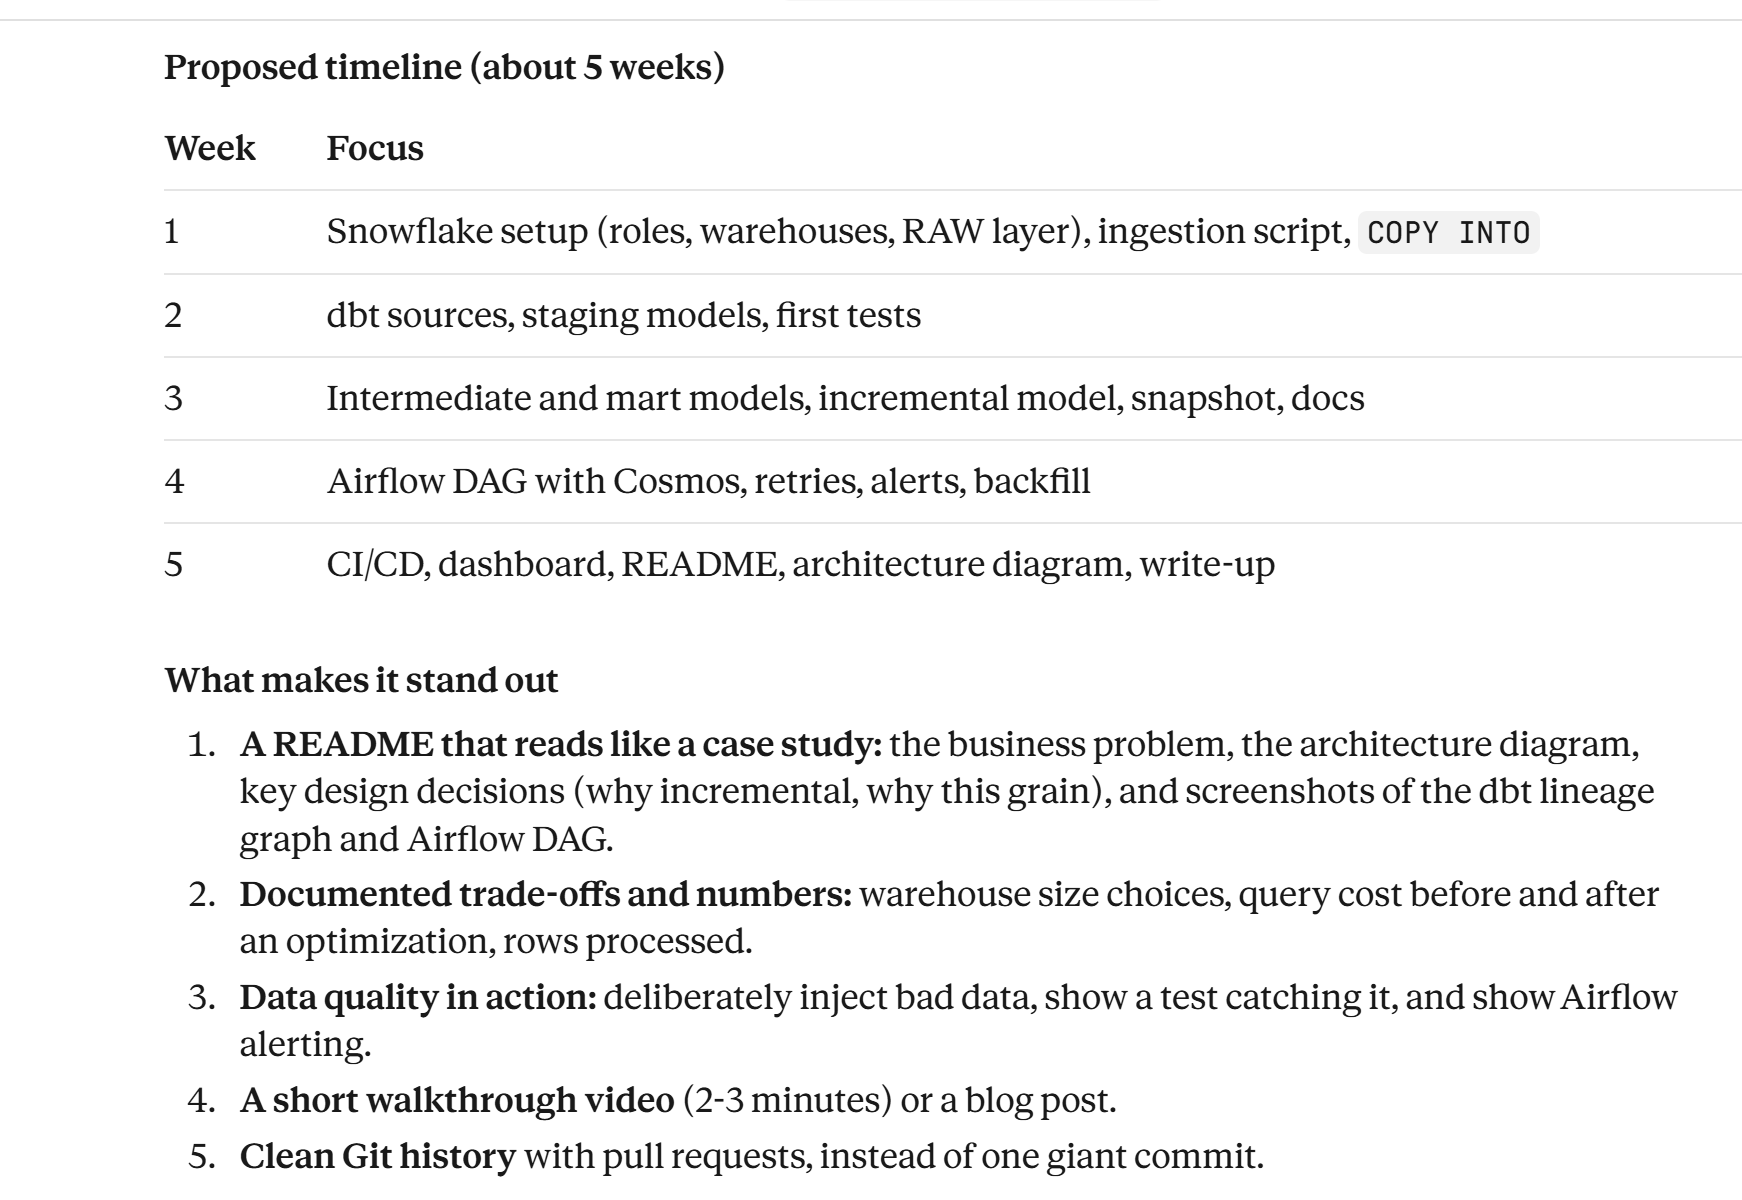

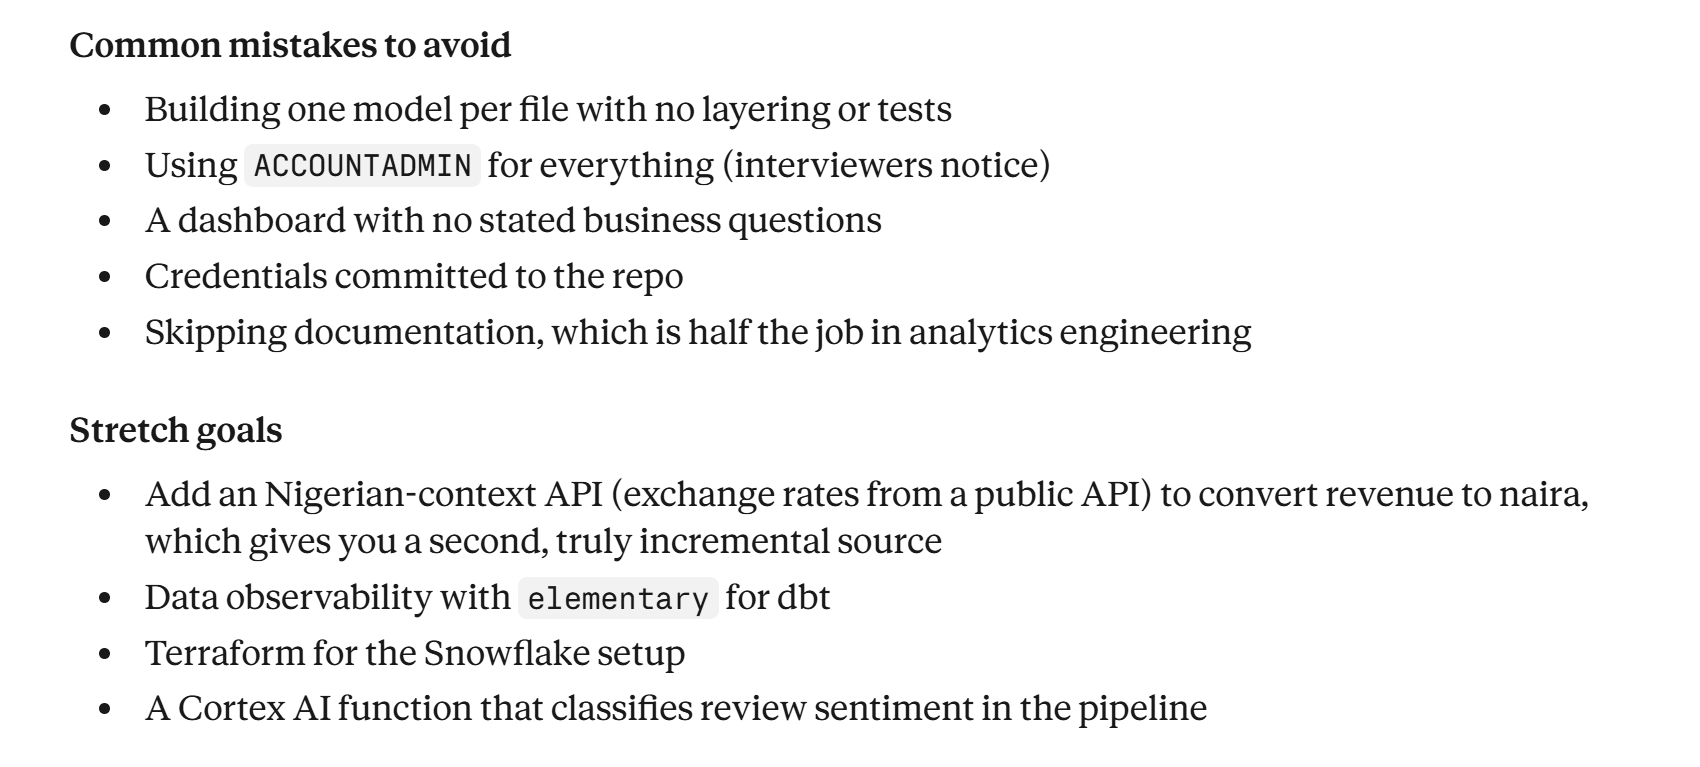